# 04 · Modelling: how much cyber damage can a company's credit absorb?

The question is the Cyber Credit Risk team's: how would a cyber incident affect a company's creditworthiness? The data hold financial statements and ratings but no incidents, so the incident-to-credit link cannot be learned from them. What they do support is the financial side: an estimate of credit quality for any company with statements (a candidate screening model of the probability of a speculative-grade rating, the engine, §1–§8), and a stress test of how large an incident each company could absorb before that estimate changes (cyber headroom, §11), also read as moves between six internal grades (§12). Only a few incidents matter for credit, so the rare-event view (§10) is part of the story. It is validated on rated companies the model never saw; whether it holds for unrated, private firms needs its own validation.

- **Input:** `data/processed/firm_years_features.csv`, `firm_years_naive_features.csv` and `features.json`, written by `03_features.ipynb` (the cleaned rows of `02_data_cleaning.ipynb` plus the credit features it selected), and `schema.json` (02).
- **Output:** `results/numbers_of_record.json` (every number quoted anywhere), `results/holdout_companies.csv`, `models/shadow_rating.pkl`, `figures/`.
- **Rules used throughout:**
  - count companies, and say "firm-years" when rows are counted;
  - every probability shown is the *calibrated probability of a speculative-grade rating*, P(SG); it is not a probability of default;
  - every choice is made on cross-validation inside the training companies; the holdout is never used for a choice. Both are quoted: CV is development evidence and may contain model-selection optimism (the model size is chosen on the same folds; the size of that effect is not measured); the holdout is the independent holdout estimate. The two time-based tests (§9, §10) split by date instead, so they use all companies.
- **Order:** everything inside the scoring file (model, calibrator, screen, grades) is set on training companies and saved first (§6); the holdout is then scored once, by the saved file loaded from disk (§7).
- **Policy:** the recommended policy is the **review budget** (review the riskiest 30% of companies). The review screen exists to give cyber headroom a line to measure distance to.
- The full-rating approach we tested (a 6-grade band, Appendix A), the tiers and the cost rule are in the appendix. Why the main product is IG/SG and not the rating is written up in `docs/why_ig_sg_not_rating.md`.

In [1]:
import hashlib
import itertools
import json
import platform
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found.*")
warnings.filterwarnings("ignore", message=".*TreeExplainer shap values output has changed.*")
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")

import cloudpickle
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from lightgbm import LGBMClassifier, LGBMRegressor
from matplotlib.colors import LinearSegmentedColormap
from scipy.optimize import brentq
from scipy.stats import beta as beta_dist, binomtest, spearmanr
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (PrecisionRecallDisplay, RocCurveDisplay, average_precision_score, brier_score_loss,
                             roc_auc_score)
from sklearn.model_selection import (GridSearchCV, GroupKFold, StratifiedGroupKFold, StratifiedKFold, learning_curve,
                                     validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer, SplineTransformer, StandardScaler

assert tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8), "fold assignment changed before scikit-learn 1.8"

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))
import cyber_credit.features, cyber_credit.preprocess  # noqa: E402,E401  (saved by value inside the model file)
from cyber_credit.features import CANDIDATES, CreditFeatures  # noqa: E402
from cyber_credit.preprocess import Winsorizer  # noqa: E402
from cyber_credit.shock import MAX_COST, TAX, assets_over_capital_employed, fit_reference, incident_shock  # noqa: E402
from cyber_credit.split import holdout_companies  # noqa: E402
DATA = ROOT / "data" / "processed"
FIG, RES = ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
NOR = {}   # numbers of record, written to results/numbers_of_record.json at the end


def keep(key, value, digits=3):
    """Store a number (or a nested dict/list of numbers) for the numbers-of-record file."""
    def r(v):
        if isinstance(v, dict): return {str(k): r(x) for k, x in v.items()}
        if isinstance(v, (list, tuple, np.ndarray)): return [r(x) for x in v]
        if isinstance(v, (bool, np.bool_)): return bool(v)
        if isinstance(v, (int, np.integer)): return int(v)
        if isinstance(v, (float, np.floating)): return round(float(v), digits) if np.isfinite(v) else None   # NaN, inf → null
        return v
    NOR[key] = r(value)

## 1. Scope and grades
All sectors, Finance included: its leverage sits within the range of the other sectors and only 2 of its 17 companies have a bank-like balance sheet (01, section 14). Banks and insurers are rated under their own agency methods; that is noted, not modelled. The 6-grade band groups the letter grades; the two ends are named 'AA and above' and 'CCC and below', because AA+ and CCC- are real one-notch ratings.

In [2]:
SCHEMA = json.loads((DATA / "schema.json").read_text())        # written by 02: the ratios, flags and bands
SPEC = json.loads((DATA / "features.json").read_text())         # written by 03: the model's inputs, chosen on training companies
FEATURES = SPEC["numeric"]     # input columns: the statement ratios kept, plus credit features held at today's value by the shock
COMPUTED = SPEC["computed"]    # credit features computed inside the model from the ratios, so they follow a shock
FLAGS = SPEC["flags"]
MARKET_PER_SHARE = SCHEMA["market_per_share"]
RATIOS = [c for c in SCHEMA["ratios"] if c not in SPEC["removed"]] + [c for c in FEATURES if c not in SCHEMA["ratios"]]
GRADES = SCHEMA["bands"]
print(f"inputs: {len(FEATURES)} columns + {len(COMPUTED)} computed + {len(FLAGS)} flags + sector | added by 03: {SPEC['added']}"
      f" | removed by 03: {SPEC['removed']}")

data = pd.read_csv(DATA / "firm_years_features.csv", parse_dates=["Date"])
data = data.reset_index(drop=True)          # all sectors, Finance included
data["grade"] = data.band_idx          # 0 = AA and above … 5 = CCC and below
data["agency"] = data["Rating Agency Name"]

print(f"in scope: {len(data)} firm-years from {data.Name.nunique()} companies | SG share of firm-years {data.SG.mean():.2f}")
keep("scope", {"firm_years": len(data), "companies": data.Name.nunique(), "sg_share_firm_years": data.SG.mean()})

inputs: 19 columns + 0 computed + 3 flags + sector | added by 03: ['implied_rate', 'op_margin_vol'] | removed by 03: ['grossProfitMargin', 'debtEquityRatio', 'companyEquityMultiplier', 'payablesTurnover', 'cogs_not_reported', 'payables_zero', 'dso_zero']
in scope: 2028 firm-years from 592 companies | SG share of firm-years 0.43


## 2. Holdout companies
One fifth of the companies is set aside, stratified on IG/SG. The list is saved, and the check below confirms the split still reproduces it. The holdout was drawn before Finance came back into scope; Finance companies are split by the same rule on their own and added, so the original 120 stay locked away.

In [3]:
holdout_names = holdout_companies(data)      # cyber_credit/split.py: one fifth of the companies, stratified on IG/SG
holdout_file = RES / "holdout_companies.csv"
if not holdout_file.exists():
    pd.Series(sorted(holdout_names), name="Name").to_csv(holdout_file, index=False)
assert holdout_names == set(pd.read_csv(holdout_file).Name), "holdout list changed"

train = data[~data.Name.isin(holdout_names)].reset_index(drop=True)
test = data[data.Name.isin(holdout_names)].reset_index(drop=True)
y_train, y_test = train.SG.values, test.SG.values
print(f"training: {train.Name.nunique()} companies ({len(train)} firm-years) | holdout: {test.Name.nunique()} companies ({len(test)} firm-years)")
keep("split", {"train_companies": train.Name.nunique(), "train_firm_years": len(train),
               "holdout_companies": test.Name.nunique(), "holdout_firm_years": len(test)})

training: 469 companies (1619 firm-years) | holdout: 123 companies (409 firm-years)


## 3. Features and model builders
- **Deployable inputs:** the statement ratios and flags kept by `03_features.ipynb`, the credit features it added (interest coverage and the others it selected, built from the ratios) and sector. They exist for an unrated, possibly private company.
- **Not deployable:** rating agency, and the three market-based and per-share features.
- Imputation and winsorising are fitted inside each training fold. LightGBM runs single-threaded and deterministic.
- Credit features marked *computed* are built inside the model from the ratios, so a cyber shock moves them; the others are input columns the shock holds at today's value (`cyber_credit/features.py` says why for each).
- The monotone inputs (count printed below): more profit, cash flow or coverage never raises risk, more debt never lowers it.

In [4]:
SAFER = ["returnOnAssets", "returnOnCapitalEmployed", "netProfitMargin", "pretaxProfitMargin", "operatingProfitMargin",
         "ebitPerRevenue", "operatingCashFlowSalesRatio", "returnOnEquity", "freeCashFlowOperatingCashFlowRatio",
         "operatingCashFlowPerShare", "freeCashFlowPerShare"]          # more = lower risk
RISKIER = ["debtRatio", "roe_negative", "negative_equity", "ocf_negative"]  # more = higher risk
for c, d in SPEC["directions"].items():                                     # the credit features' directions (03)
    if d: (SAFER if d < 0 else RISKIER).append(c)
INPUTS = {"deployable": (FEATURES, ["Sector"]), "without agency": (RATIOS, ["Sector"]), "all inputs": (RATIOS, ["Sector", "agency"])}
LEVELS = {c: sorted(data[c].unique()) for c in ["Sector", "agency"]}
LGB = {"n_estimators": 400, "learning_rate": 0.03, "num_leaves": 15, "min_child_samples": 20, "subsample": 0.8,
       "subsample_freq": 1, "colsample_bytree": 0.8, "random_state": 0, "n_jobs": 1, "deterministic": True,
       "force_row_wise": True, "verbose": -1}                       # trees and leaves are reset by the size check below
BAND_LGB = {**LGB, "n_estimators": 500}                             # the grade regressor keeps its own settings


def preprocess(inputs="deployable", kind="trees"):
    """The computed credit features, then median imputation and winsorising (plus scaling or splines for linear models), fitted per fold."""
    feats, cats = INPUTS[inputs]
    steps = [("impute", SimpleImputer(strategy="median")), ("winsor", Winsorizer())]
    if kind == "linear": steps.append(("scale", StandardScaler()))
    if kind == "spline":
        steps = [("impute", SimpleImputer(strategy="median")), ("rank", QuantileTransformer(n_quantiles=200, random_state=0)),
                 ("spline", SplineTransformer(n_knots=5, degree=3)), ("scale", StandardScaler())]
    onehot = OneHotEncoder(categories=[LEVELS[c] for c in cats], handle_unknown="ignore", sparse_output=False)
    columns = ColumnTransformer([("num", Pipeline(steps), list(feats) + COMPUTED), ("flag", "passthrough", FLAGS), ("cat", onehot, cats)])
    return Pipeline([("credit", CreditFeatures(COMPUTED)), ("columns", columns)])


def names(inputs="deployable"):
    """Column names after preprocessing, in model order."""
    feats, cats = INPUTS[inputs]
    return list(feats) + COMPUTED + FLAGS + [f"{c}={v}" for c in cats for v in LEVELS[c]]


def directions(inputs="deployable", safer=SAFER):
    """Monotone constraint per column: -1 more is safer, +1 more is riskier, 0 free."""
    return [-1 if f in safer else 1 if f in RISKIER else 0 for f in names(inputs)]


def lgbm(inputs="deployable", monotone=True, safer=SAFER, **size):
    """LightGBM classifier of P(SG), monotone by default; `size` overrides trees or leaves."""
    mono = directions(inputs, safer) if monotone else None
    return Pipeline([("pre", preprocess(inputs)), ("model", LGBMClassifier(monotone_constraints=mono, **{**LGB, **size}))])


def logistic(C=0.5, kind="linear"):
    """Logistic regression on the deployable inputs, linear or on spline features."""
    return Pipeline([("pre", preprocess(kind=kind)), ("model", LogisticRegression(C=C, max_iter=5000))])


def band_model():
    """Monotone LightGBM regressor on the 6-grade band."""
    return Pipeline([("pre", preprocess()), ("model", LGBMRegressor(monotone_constraints=directions(), **BAND_LGB))])



class CompanyWeighted(BaseEstimator, ClassifierMixin):
    """Challenger wrapper: each training company carries the same total weight (1 / its firm-years)."""
    def __init__(self, model): self.model = model
    def fit(self, X, y):
        w = 1 / X.groupby("Name").Name.transform("size").to_numpy()
        self.model_ = clone(self.model).fit(X, y, model__sample_weight=w); self.classes_ = self.model_.classes_; return self
    def predict_proba(self, X): return self.model_.predict_proba(X)


print("monotone-constrained deployable inputs:", int(np.abs(directions()).sum()))
keep("constrained_inputs", int(np.abs(directions()).sum()))

monotone-constrained deployable inputs: 15


**Validation helpers.** Folds keep every company in one fold (5 folds, seeds 11/22/33). A score is "out-of-fold" when the model that produced it never saw that company.

In [5]:
SEEDS = (11, 22, 33)


def latest(frame):
    """One row per company: its most recent statement. This is the portfolio view."""
    return frame.sort_values("Date").groupby("Name").tail(1)


def oof_runs(make_model, frame, grouped=True, seeds=SEEDS):
    """Out-of-fold scores for each seed, with the rows of each fold."""
    y, runs = frame.SG.values, []
    for seed in seeds:
        cv = (StratifiedGroupKFold(5, shuffle=True, random_state=seed) if grouped
              else StratifiedKFold(5, shuffle=True, random_state=seed))
        oof, folds = np.zeros(len(frame)), []
        for fit_rows, score_rows in cv.split(frame, y, groups=frame.Name if grouped else None):
            oof[score_rows] = make_model().fit(frame.iloc[fit_rows], y[fit_rows]).predict_proba(frame.iloc[score_rows])[:, 1]
            folds.append(score_rows)
        runs.append((oof, folds))
    return runs


def per_fold(runs, y, metric=roc_auc_score, mask=None):
    """The metric on every fold of every seed (15 values)."""
    mask = np.ones(len(y), bool) if mask is None else mask
    return np.array([metric(y[f][mask[f]], oof[f][mask[f]]) for oof, folds in runs for f in folds])


def company_weighted_auc(runs, frame):
    """Out-of-fold AUC with each company weighted equally, averaged over seeds."""
    w = 1 / frame.groupby("Name").Name.transform("size").values
    return float(np.mean([roc_auc_score(frame.SG, oof, sample_weight=w) for oof, _ in runs]))


def company_ci(stat, frame, n=2000, seed=0):
    """95% interval of stat(frame) when companies are resampled; undefined draws (one class only) are skipped."""
    rng, groups = np.random.default_rng(seed), frame.groupby("Name").indices
    keys, out = np.array(list(groups)), []
    for _ in range(n):
        rows = np.concatenate([groups[k] for k in rng.choice(keys, len(keys))])
        try: out.append(stat(frame.iloc[rows]))
        except ValueError: pass
    out = np.asarray(out, dtype=float)
    return np.percentile(out[np.isfinite(out)], [2.5, 97.5])


def size_grid(grid, frame, seeds=SEEDS):
    """Grouped-CV AUC and training-fold AUC for each setting in `grid`, with the standard error over the 15 folds."""
    folds = []
    for seed in seeds:
        search = GridSearchCV(lgbm(), grid, scoring="roc_auc", return_train_score=True,
                              cv=StratifiedGroupKFold(5, shuffle=True, random_state=seed))
        res = pd.DataFrame(search.fit(frame, frame.SG.values, groups=frame.Name).cv_results_)
        for k in range(5):
            folds.append(pd.DataFrame({"n_estimators": res.param_model__n_estimators.astype(int),
                                       "num_leaves": res.param_model__num_leaves.astype(int),
                                       "cv_auc": res[f"split{k}_test_score"], "train_auc": res[f"split{k}_train_score"]}))
    table = pd.concat(folds).groupby(["n_estimators", "num_leaves"]).agg(
        cv_auc=("cv_auc", "mean"), cv_se=("cv_auc", lambda v: v.std() / np.sqrt(len(v))), train_auc=("train_auc", "mean"))
    return table.reset_index().assign(total_leaves=lambda t: t.n_estimators * t.num_leaves)

**Model size.** Trees × leaves, scored by grouped CV on all three seeds. Rule: the smallest model (fewest leaves in total, trees × leaves per tree) whose CV AUC is within one standard error of the best. The training-fold AUC shows how much each setting memorises.

In [6]:
sizes = size_grid({"model__n_estimators": [100, 200, 400, 800], "model__num_leaves": [3, 5, 7, 10, 15]}, train)
best = sizes.loc[sizes.cv_auc.idxmax()]
chosen = sizes[sizes.cv_auc >= best.cv_auc - best.cv_se].sort_values(["total_leaves", "num_leaves"]).iloc[0]
print(sizes.pivot(index="num_leaves", columns="n_estimators", values="cv_auc").round(3).to_string())
print(f"best: {best.n_estimators:.0f} trees x {best.num_leaves:.0f} leaves, CV AUC {best.cv_auc:.3f}, one SE {best.cv_se:.3f}")
print(f"chosen: {chosen.n_estimators:.0f} trees x {chosen.num_leaves:.0f} leaves, CV AUC {chosen.cv_auc:.3f}, training-fold AUC {chosen.train_auc:.3f}")
LGB.update(n_estimators=int(chosen.n_estimators), num_leaves=int(chosen.num_leaves))
keep("model_size", {"grid": sizes.to_dict(orient="records"), "chosen_trees": chosen.n_estimators, "chosen_leaves": chosen.num_leaves,
                    "best_cv_auc": best.cv_auc, "one_se": best.cv_se, "previous_trees": 400, "previous_leaves": 15})

n_estimators    100    200    400    800
num_leaves                              
3             0.801  0.818  0.827  0.829
5             0.815  0.829  0.831  0.825
7             0.821  0.833  0.831  0.824
10            0.825  0.835  0.830  0.823
15            0.828  0.835  0.830  0.823
best: 200 trees x 10 leaves, CV AUC 0.835, one SE 0.006
chosen: 200 trees x 5 leaves, CV AUC 0.829, training-fold AUC 0.921


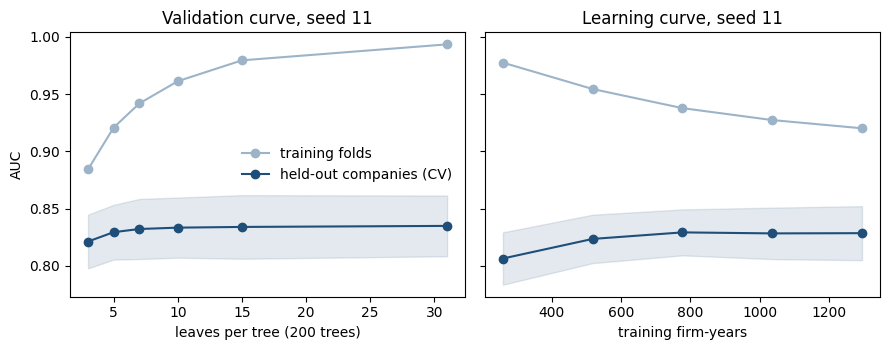

In [7]:
cv11 = StratifiedGroupKFold(5, shuffle=True, random_state=11)
leaves = [3, 5, 7, 10, 15, 31]
fit_auc, cv_auc_l = validation_curve(lgbm(), train, y_train, param_name="model__num_leaves", param_range=leaves,
                                     groups=train.Name, cv=cv11, scoring="roc_auc")
n_rows, fit_auc_n, cv_auc_n = learning_curve(lgbm(), train, y_train, groups=train.Name, cv=cv11, scoring="roc_auc",
                                             train_sizes=np.linspace(0.2, 1, 5), shuffle=True, random_state=0)
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, x, a, b in [(left, leaves, fit_auc, cv_auc_l), (right, n_rows, fit_auc_n, cv_auc_n)]:
    ax.plot(x, a.mean(1), "o-", color="#9db4c8", label="training folds")
    ax.plot(x, b.mean(1), "o-", color="#1f4e79", label="held-out companies (CV)")
    ax.fill_between(x, b.mean(1) - b.std(1), b.mean(1) + b.std(1), color="#1f4e79", alpha=0.12)
left.set_xlabel(f"leaves per tree ({LGB['n_estimators']} trees)"); left.set_ylabel("AUC"); left.legend(frameon=False, loc="center right")
right.set_xlabel("training firm-years"); left.set_title("Validation curve, seed 11"); right.set_title("Learning curve, seed 11")
fig.tight_layout(); fig.savefig(FIG / "fig_complexity.png", dpi=150); plt.show()

**Reading:** CV AUC is flat across most of the grid while the training-fold AUC keeps rising, so the extra size only memorises training companies. The gap between the curves is the overfitting a smaller model avoids.

## 4. How much a naive set-up overstates performance
The same deployable model, scored three ways on the training companies. Each step removes one source of leakage.

In [8]:
raw = pd.read_csv(DATA / "firm_years_naive_features.csv", parse_dates=["Date"])
raw = raw[raw.Name.isin(set(train.Name))].reset_index(drop=True)
raw["agency"] = raw["Rating Agency Name"]

setups = {"random split of firm-years,\nduplicates kept": oof_runs(lgbm, raw, grouped=False),
          "random split of firm-years,\nduplicates removed": oof_runs(lgbm, train, grouped=False),
          "split by company\n(deployable inputs)": oof_runs(lgbm, train)}
leak = {k: per_fold(r, (raw if "kept" in k else train).SG.values).mean() for k, r in setups.items()}
for k, v in leak.items(): print(f"{k.replace(chr(10), ' '):45s} AUC {v:.2f}")
a, b, c = leak.values()
print(f"leakage: {a - c:.2f} AUC in total = {a - b:.2f} from duplicate rows + {b - c:.2f} from the same company in train and test")
keep("leakage", {"auc_random_with_duplicates": a, "auc_random_deduplicated": b, "auc_grouped": c,
                 "total": a - b + b - c, "from_duplicates": a - b, "from_company_overlap": b - c})

random split of firm-years, duplicates kept   AUC 0.87
random split of firm-years, duplicates removed AUC 0.86
split by company (deployable inputs)          AUC 0.83
leakage: 0.04 AUC in total = 0.01 from duplicate rows + 0.03 from the same company in train and test


**What the inputs an unrated company lacks are worth** (grouped folds throughout).

In [9]:
champion_runs = setups["split by company\n(deployable inputs)"]
by_inputs = {"all inputs": oof_runs(lambda: lgbm("all inputs"), train),
             "without agency": oof_runs(lambda: lgbm("without agency"), train),
             "deployable": champion_runs}
inputs_auc = {k: per_fold(r, y_train).mean() for k, r in by_inputs.items()}
print({k: round(v, 2) for k, v in inputs_auc.items()})
keep("auc_by_inputs", inputs_auc)

{'all inputs': np.float64(0.85), 'without agency': np.float64(0.84), 'deployable': np.float64(0.83)}


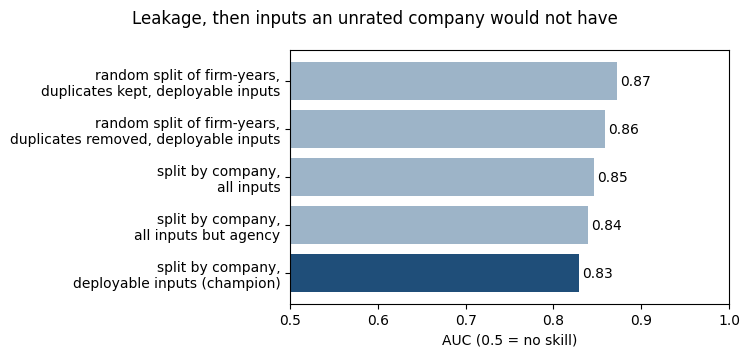

In [10]:
labels = ["random split of firm-years,\nduplicates kept, deployable inputs", "random split of firm-years,\nduplicates removed, deployable inputs",
          "split by company,\ndeployable inputs (champion)", "split by company,\nall inputs", "split by company,\nall inputs but agency"]
values = list(leak.values()) + [inputs_auc["all inputs"], inputs_auc["without agency"]]
order = [0, 1, 3, 4, 2]
fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.barh([labels[i] for i in order][::-1], [values[i] - 0.5 for i in order][::-1], left=0.5,
        color=["#1f4e79" if i == 2 else "#9db4c8" for i in order][::-1])
for y_, i in enumerate(order[::-1]): ax.text(values[i] + 0.004, y_, f"{values[i]:.2f}", va="center")
ax.set_xlim(0.5, 1.0); ax.set_xlabel("AUC (0.5 = no skill)")
fig.suptitle("Leakage, then inputs an unrated company would not have")
fig.tight_layout(); fig.savefig(FIG / "fig_leakage_waterfall.png", dpi=150); plt.show()

## 5. Model choice (cross-validation on the training companies)
All candidates use the same folds, so differences are compared fold by fold.

In [11]:
FCF_FREE = [f for f in SAFER if f != "freeCashFlowOperatingCashFlowRatio"]
candidates = {"LightGBM, monotone": champion_runs,
              "LightGBM, unconstrained": oof_runs(lambda: lgbm(monotone=False), train),
              "LightGBM, FCF/OCF unconstrained": oof_runs(lambda: lgbm(safer=FCF_FREE), train),
              "LightGBM, monotone, company-weighted": oof_runs(lambda: CompanyWeighted(lgbm()), train),
              "logistic": oof_runs(logistic, train)}
for C in [0.03, 0.1, 0.3, 1.0]:
    candidates[f"spline logistic, C={C}"] = oof_runs(lambda: logistic(C, "spline"), train)

boundary = train.Rating.isin(["BBB", "BB"]).values     # the IG/SG boundary: BBB vs BB only
champion_folds = per_fold(champion_runs, y_train)
table = pd.DataFrame({k: {"AUC": per_fold(r, y_train).mean(), "fold sd": per_fold(r, y_train).std(),
                          "vs champion": (per_fold(r, y_train) - champion_folds).mean(),
                          "sd of difference": (per_fold(r, y_train) - champion_folds).std(),
                          "company-weighted": company_weighted_auc(r, train),
                          "PR-AUC": per_fold(r, y_train, average_precision_score).mean(),
                          "BBB vs BB AUC": per_fold(r, y_train, mask=boundary).mean()} for k, r in candidates.items()}).T
print(table.round(3).to_string())
spread = table.AUC.max() - table.AUC.min()
print(f"\nmodel class moves the CV AUC by {spread:.2f} (best minus worst candidate)")
keep("model_comparison_cv", table.to_dict(orient="index"))
keep("model_class_auc_spread", spread)
keep("prauc_no_skill_cv", y_train.mean())

cw = table.loc["LightGBM, monotone, company-weighted"]
print(f"company-weighted challenger: {cw['vs champion']:+.3f} AUC vs the champion (sd of the difference {cw['sd of difference']:.3f})"
      f" | company-weighted AUC {cw['company-weighted']:.3f} vs {table.loc['LightGBM, monotone', 'company-weighted']:.3f}")
keep("company_weighted_challenger", cw.to_dict())

                                        AUC  fold sd  vs champion  sd of difference  company-weighted  PR-AUC  BBB vs BB AUC
LightGBM, monotone                    0.829    0.021        0.000             0.000             0.815   0.798          0.712
LightGBM, unconstrained               0.838    0.021        0.009             0.008             0.818   0.808          0.725
LightGBM, FCF/OCF unconstrained       0.829    0.022       -0.000             0.005             0.813   0.796          0.711
LightGBM, monotone, company-weighted  0.826    0.025       -0.003             0.011             0.814   0.792          0.708
logistic                              0.783    0.035       -0.046             0.023             0.776   0.748          0.669
spline logistic, C=0.03               0.832    0.031        0.003             0.017             0.814   0.797          0.722
spline logistic, C=0.1                0.828    0.032       -0.001             0.018             0.811   0.792          0.719


**Choice: monotone LightGBM.** The constraints cost about 0.01 AUC against the unconstrained version (a small but consistent cost; see "sd of difference"), and the spline logistic is within noise of it. It is chosen because it is the only candidate that guarantees the direction of 15 inputs (more profit or cash flow never raises risk, more debt or a higher price of debt never lowers it), which the cyber stress test relies on. The spline logistic is the transparent challenger.

**Why FCF/OCF is constrained.** Left free, the model does not read a higher FCF/OCF as safer (its SHAP rises with the value). Within sectors, the training data say a higher ratio goes with a better grade.

**Company weighting** (each company weighs the same in training, however many firm-years it has) is a challenger only. It would replace the champion only if it were better by more than the fold-to-fold noise; its line is printed above.

In [12]:
free_fcf = lgbm(safer=FCF_FREE).fit(train, y_train)
Xt = free_fcf.named_steps["pre"].transform(train)
sv_free = shap.TreeExplainer(free_fcf.named_steps["model"]).shap_values(Xt)
sv_free = sv_free[1] if isinstance(sv_free, list) else sv_free
j = names().index("freeCashFlowOperatingCashFlowRatio")
rho_free = spearmanr(Xt[:, j], sv_free[:, j]).correlation

positive_ocf = train[train.ocf_negative == 0]
within = positive_ocf.groupby("Sector").apply(lambda g: pd.Series({
    "rho": spearmanr(g.freeCashFlowOperatingCashFlowRatio, g.letter_idx).correlation,
    "n": len(g)}), include_groups=False)
rho_within = np.average(within.rho, weights=within.n)
print(f"unconstrained model: rho(value, SHAP) = {rho_free:+.2f} (positive = 'more = riskier')")
print(f"training data, within sectors: rho(FCF/OCF, letter grade) = {rho_within:+.2f} (negative = higher ratio, better grade)")
keep("fcf_ocf", {"unconstrained_rho_value_shap": rho_free, "within_sector_rho_with_grade": rho_within,
                 "auc_cost_of_constraint": -table.loc["LightGBM, FCF/OCF unconstrained", "vs champion"]})

unconstrained model: rho(value, SHAP) = +0.41 (positive = 'more = riskier')
training data, within sectors: rho(FCF/OCF, letter grade) = -0.13 (negative = higher ratio, better grade)


## 6. Calibration, the review screen, the grade scale and the saved file (training companies only)
Everything the scoring file holds is set in this section from the training companies: the champion, its calibrator, the review screen and the internal grade scale. The file is saved at the end of the section; the holdout is not touched until §7.

**Calibration.** Raw scores are mapped to probabilities with **Platt scaling**: one slope and one intercept on the log-odds. Being monotone, it changes no ranking. A slope near 1 means the raw scores were already close to calibrated in CV.

It is fitted on the out-of-fold scores of all three seeds stacked, so each score it learns from comes from one model, like the deployed model's. sklearn's `CalibratedClassifierCV` is not used: with LightGBM its `sigmoid` method fits on probabilities, not log-odds, and its `temperature` method (new in 1.8) works on log-odds but fits the slope only, with no intercept.

In [13]:
def logit(p):
    """Log-odds as a column vector, probabilities clipped away from 0 and 1."""
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6); return np.log(p / (1 - p)).reshape(-1, 1)


class Platt:
    """Platt scaling on the log-odds, fitted on the out-of-fold scores of every seed stacked."""
    def fit(self, runs, y):
        scores = np.concatenate([oof for oof, _ in runs])
        self.model_ = LogisticRegression(C=1e6).fit(logit(scores), np.tile(y, len(runs)))
        self.slope_, self.intercept_ = float(self.model_.coef_[0][0]), float(self.model_.intercept_[0])
        return self
    def __call__(self, raw_score):
        return self.model_.predict_proba(logit(raw_score))[:, 1]


def calibration_line(p, y):
    """Calibration slope (outcome regressed on logit(p)) and calibration-in-the-large (the intercept with the slope fixed at 1,
    so 0 = right on average, below 0 = predicts too high); calibrated = (1, 0)."""
    z, y = logit(p).ravel(), np.asarray(y, dtype=float)
    slope = float(LogisticRegression(C=1e6).fit(z.reshape(-1, 1), y).coef_[0][0])
    citl = brentq(lambda a: np.sum(y - 1 / (1 + np.exp(-(a + z)))), -10, 10)   # no root when one class only: company_ci skips the draw
    return slope, float(citl)


platt = Platt().fit(champion_runs, y_train)
champion = lgbm().fit(train, y_train)
p_sg = lambda frame: platt(champion.predict_proba(frame)[:, 1])   # the calibrated P(SG) shown to people

assert not np.isnan(champion.named_steps["pre"].transform(train)).any()   # no missing value reaches the model

print(f"Platt slope on out-of-fold scores: {platt.slope_:.2f} (below 1 = raw scores over-confident)")
keep("platt", {"slope": platt.slope_, "intercept": platt.intercept_})

Platt slope on out-of-fold scores: 1.06 (below 1 = raw scores over-confident)


**The review screen** has one job: it is the line cyber headroom (§11) measures distance to. Its threshold is set on the latest statement of each training company, scored out of fold, so that it catches 85% of the SG *companies* (the unit the review works on). It is stated as a calibrated P(SG).

In [14]:
def screen_threshold(scores, y, recall):
    """Lowest score still needed to catch the given share of SG rows."""
    order = np.sort(scores[y == 1])[::-1]; return order[int(np.ceil(recall * len(order))) - 1]


cv_portfolios = [latest(train.assign(p_sg=platt(oof))) for oof, _ in champion_runs]   # one per seed: latest statement per company, out of fold
company_scores = np.concatenate([f.p_sg.to_numpy() for f in cv_portfolios])
company_sg = np.concatenate([f.SG.to_numpy() for f in cv_portfolios])
SCREEN = screen_threshold(company_scores, company_sg, 0.85)          # calibrated P(SG), set on companies, out of fold
print(f"screen = calibrated P(SG) >= {SCREEN:.2f} (catches 85% of SG training companies on their latest statement, out of fold)")

screen = calibrated P(SG) >= 0.28 (catches 85% of SG training companies on their latest statement, out of fold)


**The internal grade scale.** Credit teams read risk as grades, and change as moves between grades. The calibrated P(SG) is grouped into six internal grades, set here on the training companies and saved in the file; §12 checks them on the holdout and shows the cyber result as moves between them.

- **A screening scale, not a regulatory master scale.** Bank internal-ratings rules require at least 7 grades for non-defaulted borrowers plus 1 for default (Basel II para 404; CRR Art 170(1)(b)). The number of grades is chosen on training companies only: the binning below is fitted on four-fifths of them and read on the other fifth (25 company splits), and the rule, fixed in advance, takes the most grades whose SG rate rises grade by grade in at least 90% of splits. That is six (4, 5 and 6 grades: 100% of splits; 7: 84%); the check stops the notebook if it changes. Before the credit features of 03 the same rule gave five (6 grades: 84%): the better ranking supports one more grade. More data would allow more (see monitoring, at the end of §12).
- **Cut-offs chosen by the data.** Monotone optimal binning on the out-of-fold training scores: the cut-points that best fit each grade's SG rate, with the SG rate rising grade by grade and at least 10% of firm-years in every grade. Round cut-offs are used instead: the set on a 0.05 grid that passes the optimum's own rules and keeps the most of its fit, 0.15 / 0.3 / 0.5 / 0.7 / 0.85 (the share kept and the optimum are printed below; it must be at least 95%); the check stops the notebook if that changes.
- **Named after the decision, not agency letters:** one cut-off is P(SG) = 0.5, the model's SG call, so IG-1, IG-2 and IG-3 sit below it and SG-1, SG-2 and SG-3 above it. Agency letters would claim a precision the model does not have (§5 and Appendix A); each grade instead shows the agency ratings its companies actually hold.
- **Each grade carries an observed SG rate, not a PD:** P(SG) is not a probability of default.
- **One rule on top:** negative equity puts a company at SG-1 or worse (§12 shows what it changes).

In [15]:
GRADE_NAMES = ["IG-1", "IG-2", "IG-3", "SG-1", "SG-2", "SG-3"]   # the cut at 0.5 is the model's SG call: three grades on each side
GRADE_MEANING = ["strong", "solid", "near the line", "near the line", "weak", "very weak"]
GRADE_CUTS = [0.15, 0.3, 0.5, 0.7, 0.85]                 # calibrated P(SG); checked against the optimum below
GRADE_SCALE = {"cuts": GRADE_CUTS, "names": GRADE_NAMES, "rule": "negative equity: SG-1 or worse"}


def optimal_cuts(p, y, k, min_share=0.10, grid=50):
    """Monotone optimal binning by dynamic programming: the k-1 cut-points, from a quantile grid of p, that maximise the binomial
    log-likelihood of the grades' SG rates, with the SG rate rising grade by grade and every grade holding at least min_share of rows."""
    edges = np.concatenate([[-np.inf], np.unique(np.quantile(p, np.linspace(0, 1, grid + 1)[1:-1])), [np.inf]])
    order = np.argsort(p)
    pos, cum = np.searchsorted(p[order], edges), np.concatenate([[0], np.cumsum(y[order])])

    def fit(i, j):
        """Log-likelihood and SG rate of the grade between edges i and j; None when it is too small."""
        n = pos[j] - pos[i]
        if n < min_share * len(p): return None
        d = cum[pos[j]] - cum[pos[i]]; r = d / n
        return (d * np.log(r) if d else 0.0) + ((n - d) * np.log(1 - r) if n > d else 0.0), r

    best = {(0, 0): (0.0, -1.0, [])}          # (grades so far, last edge) -> (log-likelihood, last SG rate, edges used)
    for g in range(1, k + 1):
        for j in ([len(edges) - 1] if g == k else range(1, len(edges))):
            options = []
            for i in range(j):
                if (g - 1, i) in best and (f := fit(i, j)) and f[1] > best[(g - 1, i)][1]:
                    options.append((best[(g - 1, i)][0] + f[0], f[1], best[(g - 1, i)][2] + [j]))
            if options: best[(g, j)] = max(options, key=lambda o: o[0])
    return [float(edges[j]) for j in best[(k, len(edges) - 1)][2][:-1]]


def to_grade(p, cuts=GRADE_CUTS):
    """Grade index of each calibrated P(SG): 0 = IG-1 ... 4 = SG-2."""
    return np.searchsorted(np.asarray(cuts), np.asarray(p, dtype=float), side="right")


def assign_grade(frame, p, cuts=GRADE_CUTS, names=GRADE_NAMES):
    """The internal grade: the P(SG) grade, then the rule that negative equity means SG-1 or worse. Returns (grade, rule moved it)."""
    g = to_grade(p, cuts)
    floor = np.where(frame.negative_equity.to_numpy() == 1, names.index("SG-1"), 0)
    return np.maximum(g, floor), floor > g


dev_p = np.concatenate([platt(oof) for oof, _ in champion_runs])     # out of fold, calibrated, the three seeds stacked
dev_y = np.tile(y_train, len(champion_runs))
def grade_fit(p, y, cuts):
    """Binomial log-likelihood per row of the grades' SG rates: how well a set of cut-offs fits (higher is better)."""
    g, ll = to_grade(p, cuts), 0.0
    for k in np.unique(g):
        n, d = (g == k).sum(), y[g == k].sum(); r = d / n
        ll += (d * np.log(r) if d else 0.0) + ((n - d) * np.log(1 - r) if n > d else 0.0)
    return ll / len(p)


optimum = optimal_cuts(dev_p, dev_y, len(GRADE_NAMES))
fixed_share = np.bincount(to_grade(dev_p), minlength=len(GRADE_NAMES)) / len(dev_p)
fixed_rate = pd.Series(dev_y).groupby(to_grade(dev_p)).mean().reindex(range(len(GRADE_NAMES))).to_numpy()
# The round cut-offs pass the optimum's own rules on the training scores, keep at least 95% of its fit, and are the best such set on a
# 0.05 grid; the holdout is never used to choose
assert fixed_share.min() >= 0.10 and np.all(np.diff(fixed_rate) > 0), f"the round cut-offs fail: shares {fixed_share}, SG rates {fixed_rate}"
fit_fixed, fit_opt, fit_none = grade_fit(dev_p, dev_y, GRADE_CUTS), grade_fit(dev_p, dev_y, optimum), grade_fit(dev_p, dev_y, [])
fit_kept = (fit_fixed - fit_none) / (fit_opt - fit_none)
assert fit_kept >= 0.95, f"the round cut-offs keep only {fit_kept:.1%} of the optimum's fit"


def passes(cuts):
    """The optimum's own rules: every grade holds at least 10% of rows and the SG rate rises grade by grade."""
    g = to_grade(dev_p, cuts); share = np.bincount(g, minlength=len(cuts) + 1) / len(dev_p)
    rate = pd.Series(dev_y).groupby(g).mean().reindex(range(len(cuts) + 1)).to_numpy()
    return share.min() >= 0.10 and np.all(np.diff(rate) > 0)


grid_05 = np.round(np.arange(0.05, 1.0, 0.05), 2)
round_best = max((list(c) for c in itertools.combinations(grid_05, len(GRADE_NAMES) - 1) if passes(list(c))),
                 key=lambda c: grade_fit(dev_p, dev_y, c))
assert np.allclose(round_best, GRADE_CUTS), f"the best round cut-offs on the 0.05 grid are {round_best}, not {GRADE_CUTS}"
print(f"{len(GRADE_NAMES)}-grade optimum {np.round(optimum, 3).tolist()} | used {GRADE_CUTS}: share of rows by grade {fixed_share.round(2).tolist()},"
      f" SG rate {fixed_rate.round(2).tolist()}")
print(f"share of the optimum's fit (gain over no grades) that the round cut-offs keep: {fit_kept:.1%} (the best set on a 0.05 grid)")

# How many grades, on training companies only: the binning is fitted on 4/5 of them and read on the other 1/5 (5 x 5 company splits).
# Rule fixed in advance: the most grades whose SG rate rises grade by grade in at least 90% of the splits.
dev_by_seed = dev_p.reshape(len(champion_runs), len(train))
grade_count = {}
for k in (4, 5, 6, 7):
    rises = []
    for rep in range(5):
        for fit_rows, held_rows in GroupKFold(5, shuffle=True, random_state=rep).split(train, groups=train.Name):
            cuts_k = optimal_cuts(dev_by_seed[:, fit_rows].ravel(), np.tile(y_train[fit_rows], len(champion_runs)), k)
            held_y = pd.Series(np.tile(y_train[held_rows], len(champion_runs)))
            rates = held_y.groupby(to_grade(dev_by_seed[:, held_rows].ravel(), cuts_k)).mean().reindex(range(k)).to_numpy()
            rises.append(bool(np.all(np.diff(rates) > 0)))
    grade_count[k] = float(np.mean(rises))
n_grades = max(k for k, share in grade_count.items() if share >= 0.9)
print("SG rate rises grade by grade on held-out training companies, share of 25 splits:", {k: f"{v:.0%}" for k, v in grade_count.items()})
assert n_grades == len(GRADE_NAMES), f"the training check supports {n_grades} grades, not {len(GRADE_NAMES)}"

6-grade optimum [0.173, 0.308, 0.501, 0.68, 0.879] | used [0.15, 0.3, 0.5, 0.7, 0.85]: share of rows by grade [0.2, 0.23, 0.21, 0.13, 0.11, 0.12], SG rate [0.09, 0.22, 0.4, 0.6, 0.77, 0.92]
share of the optimum's fit (gain over no grades) that the round cut-offs keep: 99.5% (the best set on a 0.05 grid)


SG rate rises grade by grade on held-out training companies, share of 25 splits: {4: '100%', 5: '100%', 6: '100%', 7: '84%'}


**The scoring file.** The fitted preprocessing and classifier, the calibrator, the screen, the internal grade scale and its rule (above), the input schema and version metadata are saved as one file, `models/shadow_rating.pkl`. It is written with cloudpickle, so the classes defined in this notebook travel with it: loading needs the packages in `requirements.txt`, not this notebook. Load only a copy you trust, because unpickling runs code. The check below reloads the file and reproduces the training-company scores; §7 then scores the holdout with this file, as loaded from disk.

**Input contract.** `score()` takes rows as written by `03_features.ipynb` (`firm_years_features.csv`: cleaned, with rebuilt ratios, flags and the selected input features), not the raw file: cleaning and the input features are not part of the artifact; the computed credit features are. It rejects missing or non-numeric input columns, infinite values and flags other than 0/1, and warns when a sector was not seen in training (scored with no sector effect). The checks below confirm each rule.

In [16]:
class ShadowRating:
    """Scores processed firm-years: calibrated P(SG), the screen flag and the internal grade (§6).

    Input: rows as written by 03_features.ipynb (data/processed/firm_years_features.csv), NOT the raw file. Cleaning, the rebuilt
    ratios, the flags and the input features are not part of this object; the computed credit features are (the model's first step).
    score() checks the input contract first."""
    def __init__(self, model, calibrator, screen, schema, sectors, grades, metadata):
        self.model, self.calibrator, self.screen, self.schema, self.sectors, self.grades, self.metadata = (
            model, calibrator, screen, schema, sectors, grades, metadata)
    def check(self, frame):
        """Raise on a broken input contract; warn on a sector not seen in training."""
        numeric = self.schema["inputs"] + self.schema["flags"]
        missing = [c for c in numeric + ["Sector"] if c not in frame.columns]
        if missing: raise ValueError(f"missing input columns: {missing}. score() needs the output of 03_features.ipynb, not raw data")
        not_numeric = [c for c in numeric if not pd.api.types.is_numeric_dtype(frame[c])]
        if not_numeric: raise ValueError(f"non-numeric input columns: {not_numeric}")
        infinite = [c for c in numeric if np.isinf(frame[c].to_numpy(dtype=float)).any()]
        if infinite: raise ValueError(f"infinite values in: {infinite}")
        bad_flags = [c for c in self.schema["flags"] if not frame[c].isin([0, 1]).all()]
        if bad_flags: raise ValueError(f"flags must be 0 or 1: {bad_flags}")
        unseen = sorted(set(frame.Sector.dropna()) - set(self.sectors))
        if unseen: warnings.warn(f"sectors not seen in training, scored with no sector effect: {unseen}")
    def score(self, frame):
        self.check(frame)
        with warnings.catch_warnings():      # LightGBM notice from the pipeline's array hand-off; it changes nothing
            warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")
            p = self.calibrator(self.model.predict_proba(frame)[:, 1])
        g, moved = assign_grade(frame, p, self.grades["cuts"], self.grades["names"])
        return pd.DataFrame({"p_sg": p, "screen": p >= self.screen, "grade": np.asarray(self.grades["names"])[g], "grade_rule": moved},
                            index=frame.index)


metadata = {"model": "LightGBM, monotone", "trees": LGB["n_estimators"], "leaves": LGB["num_leaves"], "screen_calibrated_psg": float(SCREEN), "grade_cuts": GRADE_CUTS, "grade_names": GRADE_NAMES,
            "training_companies": train.Name.nunique(), "training_firm_years": len(train),
            "data_sha256": hashlib.sha256((DATA / "firm_years_features.csv").read_bytes()).hexdigest(), "added_features": SPEC["added"],
            "removed_inputs": SPEC["removed"], "python": platform.python_version(),
            "packages": {m.__name__: m.__version__ for m in (np, pd, sklearn, lightgbm, cloudpickle)}}
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
MODEL_SCHEMA = {**SCHEMA, "features": FEATURES + COMPUTED, "inputs": FEATURES, "computed": COMPUTED, "flags": FLAGS}   # model column order
for module in (cyber_credit.features, cyber_credit.preprocess):
    cloudpickle.register_pickle_by_value(module)        # the file carries this code, so it loads without the repository
(MODELS / "shadow_rating.pkl").write_bytes(cloudpickle.dumps(ShadowRating(champion, platt, float(SCREEN), MODEL_SCHEMA, LEVELS["Sector"], GRADE_SCALE, metadata)))

reloaded = cloudpickle.loads((MODELS / "shadow_rating.pkl").read_bytes())
assert np.allclose(reloaded.score(train).p_sg, p_sg(train)) and (reloaded.score(train).screen == (p_sg(train) >= SCREEN)).all()
assert (reloaded.score(train).grade.to_numpy() == np.asarray(GRADE_NAMES)[assign_grade(train, p_sg(train))[0]]).all()


def rejected(frame):
    """True when score() refuses the frame."""
    try: reloaded.score(frame)
    except ValueError: return True
    return False


rows3 = train.head(3)
assert rejected(rows3.drop(columns="debtRatio")) and rejected(rows3.assign(debtRatio=np.inf))
assert rejected(rows3.assign(currentRatio=rows3.currentRatio.astype(str))) and rejected(rows3.assign(roe_negative=2))
with warnings.catch_warnings(record=True) as caught_w:
    warnings.simplefilter("always"); reloaded.score(rows3.assign(Sector="Not a sector"))
assert any("not seen in training" in str(w.message) for w in caught_w)
print("input contract checks passed")
print("models/shadow_rating.pkl reloads and reproduces the training-company scores |", {k: v for k, v in metadata.items() if k != "packages"})
keep("artifact", {"path": "models/shadow_rating.pkl", **metadata})

input contract checks passed
models/shadow_rating.pkl reloads and reproduces the training-company scores | {'model': 'LightGBM, monotone', 'trees': 200, 'leaves': 5, 'screen_calibrated_psg': 0.2807022684705826, 'grade_cuts': [0.15, 0.3, 0.5, 0.7, 0.85], 'grade_names': ['IG-1', 'IG-2', 'IG-3', 'SG-1', 'SG-2', 'SG-3'], 'training_companies': 469, 'training_firm_years': 1619, 'data_sha256': '186a51e6fefe4eb0ace8ec1600ed517992047af6ebd5f8445f55913e73142628', 'added_features': ['implied_rate', 'op_margin_vol'], 'removed_inputs': ['grossProfitMargin', 'debtEquityRatio', 'companyEquityMultiplier', 'payablesTurnover', 'cogs_not_reported', 'payables_zero', 'dso_zero'], 'python': '3.13.16'}


## 7. The holdout: the saved file, scored once
The 123 holdout companies are scored by `models/shadow_rating.pkl` as loaded from disk, the exact file that is handed over, not by the objects in memory. Everything in this section is a check: nothing is chosen on the holdout.

In [17]:
SHADOW = cloudpickle.loads((MODELS / "shadow_rating.pkl").read_bytes())      # the saved file, read back from disk
holdout_scores = SHADOW.score(test)
test["p_raw"] = SHADOW.model.predict_proba(test)[:, 1]                         # raw model score, before the calibrator
test["p_sg"] = holdout_scores.p_sg                                              # calibrated P(SG), as the file gives it
assert np.allclose(SHADOW.calibrator(test.p_raw), test.p_sg)
assert not np.isnan(SHADOW.model.named_steps["pre"].transform(test)).any()   # no missing value reaches the model
print(f"holdout: {test.Name.nunique()} companies ({len(test)} firm-years) scored by models/shadow_rating.pkl")

holdout: 123 companies (409 firm-years) scored by models/shadow_rating.pkl


**Calibration on the holdout** (companies resampled for the intervals). A calibrated model has slope 1 and calibration-in-the-large 0: the intercept with the slope fixed at 1, so 0 means the average P(SG) matches the SG share and below 0 means P(SG) runs too high.

In [18]:
cal = {}
for col, label in [("p_raw", "raw score"), ("p_sg", "calibrated")]:
    s, i = calibration_line(test[col], test.SG)
    s_ci = company_ci(lambda f: calibration_line(f[col], f.SG)[0], test, n=1000)
    i_ci = company_ci(lambda f: calibration_line(f[col], f.SG)[1], test, n=1000)
    cal[label] = {"slope": s, "slope_ci": s_ci, "in_the_large": i, "in_the_large_ci": i_ci, "brier": brier_score_loss(test.SG, test[col])}
    print(f"{label:11s} slope {s:.2f} [{s_ci[0]:.2f}, {s_ci[1]:.2f}] | in the large {i:+.2f} [{i_ci[0]:+.2f}, {i_ci[1]:+.2f}] | Brier {cal[label]['brier']:.3f}")
quint = test.groupby(pd.qcut(test.p_sg, 5, labels=False)).agg(predicted=("p_sg", "mean"), actual=("SG", "mean"))
print("calibrated P(SG) by quintile, predicted vs actual share:\n", quint.round(2).T.to_string())
keep("calibration_holdout", {**cal, "quintiles": quint.to_dict(orient="list")})

raw score   slope 0.92 [0.67, 1.24] | in the large -0.11 [-0.55, +0.32] | Brier 0.178


calibrated  slope 0.87 [0.63, 1.17] | in the large -0.11 [-0.57, +0.33] | Brier 0.179
calibrated P(SG) by quintile, predicted vs actual share:
 p_sg          0     1     2     3     4
predicted  0.11  0.22  0.38  0.64  0.88
actual     0.11  0.32  0.35  0.46  0.90


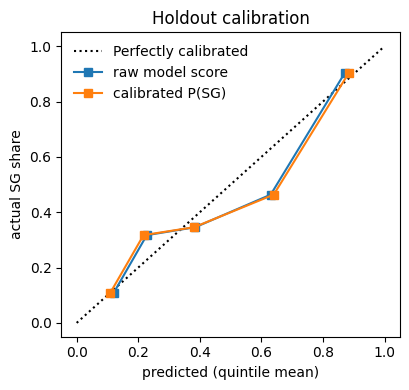

In [19]:
fig, ax = plt.subplots(figsize=(4.2, 4))
for col, label in [("p_raw", "raw model score"), ("p_sg", "calibrated P(SG)")]:
    CalibrationDisplay.from_predictions(test.SG, test[col], n_bins=5, strategy="quantile", name=label, ax=ax)
ax.set_xlabel("predicted (quintile mean)"); ax.set_ylabel("actual SG share")
ax.set_title("Holdout calibration"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig_calibration.png", dpi=150); plt.show()

**Reading:** calibrated on cross-validation; on the holdout the fourth fifth runs high (0.64 predicted vs 0.46 actual) and the second runs low (0.22 vs 0.32). Calibration-in-the-large is below 0 (P(SG) runs a little high on average), but its interval includes 0. Read them as a ranking with an approximate level.

Calibration is approximate in two further ways: the calibrator learns from fold models trained on 80% of the training companies and is then applied to the final model, and companies with more firm-years weigh more in it. It is calibrated to rated companies, where 43% of firm-years are SG; for unrated private firms the level needs its own check. If their SG share differs, shift the calibrator's intercept by logit(their share) − logit(43%) and confirm it on a labelled sample: the ranking carries over, but the screen and the grade cut-offs are in P(SG) units and move with the level.

**The review budget is the recommended policy.** Analysts review the riskiest X% of companies; it starts from analyst capacity, the real constraint. Portfolio numbers use one row per company (its latest statement).

In [20]:
def budget_catch(frame, share, score="p_sg"):
    """Share of SG companies caught, and precision, when the riskiest `share` of companies is reviewed."""
    top = frame.nlargest(round(share * len(frame)), score); return top.SG.sum() / frame.SG.sum(), top.SG.mean()


portfolio = latest(test).copy()
rows = []
for share in [0.2, 0.3, 0.4, 0.5]:
    cv_catch = np.mean([budget_catch(f, share)[0] for f in cv_portfolios])
    te_catch, te_prec = budget_catch(portfolio, share)
    ci = company_ci(lambda f: budget_catch(f, share)[0], portfolio)
    rows.append({"budget": share, "SG caught (CV)": cv_catch, "SG caught (holdout)": te_catch,
                 "95% CI": f"[{ci[0]:.2f}, {ci[1]:.2f}]", "precision (holdout)": te_prec, "random ranking": share})
budget = pd.DataFrame(rows)
print(budget.round(2).to_string(index=False))
keep("review_budget_companies", budget.to_dict(orient="records"))

 budget  SG caught (CV)  SG caught (holdout)       95% CI  precision (holdout)  random ranking
    0.2            0.38                 0.38 [0.30, 0.47]                 0.84             0.2
    0.3            0.54                 0.54 [0.46, 0.64]                 0.81             0.3
    0.4            0.66                 0.68 [0.57, 0.76]                 0.78             0.4
    0.5            0.75                 0.77 [0.67, 0.86]                 0.69             0.5


In [21]:
portfolio["screen"] = portfolio.p_sg >= SCREEN
in_budget = portfolio.p_sg.rank(ascending=False, method="first") <= round(0.3 * len(portfolio))
portfolio["group"] = np.select([in_budget, portfolio.screen], ["in the 30% review budget", "on the screen, outside the budget"], "below the screen")

flagged = lambda f: f.screen.mean()
caught = lambda f: f.screen[f.SG == 1].mean()
f_ci, c_ci = company_ci(flagged, portfolio), company_ci(caught, portfolio)
print(f"holdout, {len(portfolio)} companies: flags {flagged(portfolio):.0%} [{f_ci[0]:.0%}, {f_ci[1]:.0%}] "
      f"| catches {caught(portfolio):.0%} of SG companies [{c_ci[0]:.0%}, {c_ci[1]:.0%}]")
print("review groups:", portfolio.group.value_counts().to_dict())
keep("screen", {"threshold_calibrated_psg": SCREEN, "target_recall_oof": 0.85, "set_on": "latest statement per training company, out of fold",
                "holdout_companies": len(portfolio), "flagged_share": flagged(portfolio), "flagged_ci": f_ci,
                "sg_recall": caught(portfolio), "sg_recall_ci": c_ci})

holdout, 123 companies: flags 67% [59%, 75%] | catches 88% of SG companies [79%, 96%]
review groups: {'on the screen, outside the budget': 45, 'below the screen': 41, 'in the 30% review budget': 37}


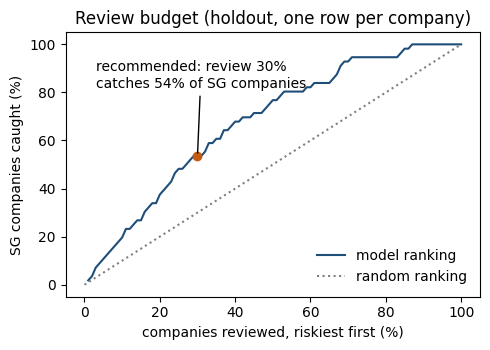

In [22]:
shares = np.linspace(0.01, 1, 100)
fig, ax = plt.subplots(figsize=(5, 3.6))
ax.plot(shares * 100, [budget_catch(portfolio, s)[0] * 100 for s in shares], color="#1f4e79", label="model ranking")
ax.plot([0, 100], [0, 100], ":", color="grey", label="random ranking")
c30 = budget_catch(portfolio, 0.3)[0] * 100
ax.scatter([30], [c30], color="#c55a11", zorder=3)
ax.annotate(f"recommended: review 30%\ncatches {c30:.0f}% of SG companies", (30, c30), xytext=(3, 82), arrowprops=dict(arrowstyle="-"))
ax.set_xlabel("companies reviewed, riskiest first (%)"); ax.set_ylabel("SG companies caught (%)")
ax.set_title("Review budget (holdout, one row per company)"); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "fig_workload.png", dpi=150); plt.show()

**Headline accuracy, both quoted.** Cross-validation on the training companies is development evidence and may contain model-selection optimism: the model size was chosen on the same folds. The holdout, read once, is the independent holdout estimate; with 123 companies its interval is wide.

In [23]:
cv_auc = per_fold(champion_runs, y_train)
auc_test = roc_auc_score(test.SG, test.p_sg)
auc_ci = company_ci(lambda f: roc_auc_score(f.SG, f.p_sg), test)
ap_test = average_precision_score(test.SG, test.p_sg)
bb = test.Rating.isin(["BBB", "BB"])
print(f"CV AUC {cv_auc.mean():.2f} ± {cv_auc.std():.2f} (fold mean ± sd) | company-weighted {company_weighted_auc(champion_runs, train):.2f}"
      " (development estimate; may contain model-selection optimism)")
print(f"holdout AUC {auc_test:.2f} [{auc_ci[0]:.2f}, {auc_ci[1]:.2f}] | PR-AUC {ap_test:.2f} (no skill {test.SG.mean():.2f})"
      " (the independent holdout estimate)")
print(f"BBB vs BB: CV {table.loc['LightGBM, monotone', 'BBB vs BB AUC']:.2f} | holdout {roc_auc_score(test.SG[bb], test.p_sg[bb]):.2f}")
print(f"the holdout interval {'includes' if auc_ci[1] >= cv_auc.mean() else 'excludes'} the CV mean")
keep("headline", {"cv_auc_mean": cv_auc.mean(), "cv_auc_sd": cv_auc.std(), "cv_auc_company_weighted": company_weighted_auc(champion_runs, train),
                  "cv_prauc": table.loc["LightGBM, monotone", "PR-AUC"], "holdout_auc": auc_test, "holdout_auc_ci": auc_ci,
                  "holdout_prauc": ap_test, "holdout_prauc_no_skill": test.SG.mean(),
                  "boundary_auc_cv": table.loc["LightGBM, monotone", "BBB vs BB AUC"],
                  "boundary_auc_holdout": roc_auc_score(test.SG[bb], test.p_sg[bb])})

CV AUC 0.83 ± 0.02 (fold mean ± sd) | company-weighted 0.81 (development estimate; may contain model-selection optimism)
holdout AUC 0.80 [0.72, 0.87] | PR-AUC 0.78 (no skill 0.43) (the independent holdout estimate)
BBB vs BB: CV 0.71 | holdout 0.69
the holdout interval includes the CV mean


**The same checks on companies.** The review works on each company's latest statement, so the holdout is also scored with one row per company (123 rows; the bootstrap resamples companies).

In [24]:
lat = portfolio
auc_c, auc_c_ci = roc_auc_score(lat.SG, lat.p_sg), company_ci(lambda f: roc_auc_score(f.SG, f.p_sg), lat)
ap_c = average_precision_score(lat.SG, lat.p_sg)
s_c, i_c = calibration_line(lat.p_sg, lat.SG)
s_c_ci = company_ci(lambda f: calibration_line(f.p_sg, f.SG)[0], lat, n=1000)
i_c_ci = company_ci(lambda f: calibration_line(f.p_sg, f.SG)[1], lat, n=1000)
quint_c = lat.groupby(pd.qcut(lat.p_sg, 5, labels=False)).agg(predicted=("p_sg", "mean"), actual=("SG", "mean"))
print(f"holdout, latest statement per company ({len(lat)} companies): AUC {auc_c:.2f} [{auc_c_ci[0]:.2f}, {auc_c_ci[1]:.2f}]"
      f" | PR-AUC {ap_c:.2f} (no skill {lat.SG.mean():.2f})")
print(f"calibration slope {s_c:.2f} [{s_c_ci[0]:.2f}, {s_c_ci[1]:.2f}] | in the large {i_c:+.2f} [{i_c_ci[0]:+.2f}, {i_c_ci[1]:+.2f}]"
      f" | Brier {brier_score_loss(lat.SG, lat.p_sg):.3f}")
print("calibrated P(SG) by quintile, predicted vs actual share:\n", quint_c.round(2).T.to_string())
keep("holdout_latest_company", {"companies": len(lat), "auc": auc_c, "auc_ci": auc_c_ci, "prauc": ap_c, "prauc_no_skill": lat.SG.mean(),
                                "calibration_slope": s_c, "slope_ci": s_c_ci, "calibration_in_the_large": i_c, "in_the_large_ci": i_c_ci,
                                "brier": brier_score_loss(lat.SG, lat.p_sg), "quintiles": quint_c.to_dict(orient="list")})

holdout, latest statement per company (123 companies): AUC 0.82 [0.74, 0.89] | PR-AUC 0.80 (no skill 0.46)
calibration slope 0.92 [0.66, 1.32] | in the large -0.27 [-0.71, +0.20] | Brier 0.173
calibrated P(SG) by quintile, predicted vs actual share:
 p_sg          0     1     2     3     4
predicted  0.12  0.27  0.47  0.72  0.91
actual     0.12  0.29  0.32  0.71  0.84


**Overfitting check.** The same AUC on the training companies (in-sample), in CV and on the holdout, for the chosen size and the previous one (400 trees, 15 leaves).

In [25]:
fits = {"chosen": champion, "previous": lgbm(n_estimators=400, num_leaves=15).fit(train, y_train)}
overfit = pd.DataFrame({k: {"training companies (in-sample)": roc_auc_score(y_train, m.predict_proba(train)[:, 1]),
                            "CV": sizes.set_index(["n_estimators", "num_leaves"]).cv_auc[(m[-1].n_estimators, m[-1].num_leaves)],
                            "holdout": roc_auc_score(test.SG, m.predict_proba(test)[:, 1])} for k, m in fits.items()}).T
print(overfit.round(3).to_string())
keep("overfitting_auc", overfit.to_dict(orient="index"))

          training companies (in-sample)     CV  holdout
chosen                             0.909  0.829    0.799
previous                           0.995  0.830    0.792


**Stability of the model itself** (a challenger check, not a choice). The champion is refitted on 20 bootstrap samples of the training companies, and each holdout company's calibrated P(SG) is recomputed with every refit. The calibrator and the screen threshold are held fixed, so this measures sensitivity to which companies were in training, given those choices; it is not the uncertainty of the whole pipeline. The last line checks whether the less stable screen decisions are the ones close to the screen.

In [26]:
rng_s = np.random.default_rng(0)
groups_s = train.groupby("Name").indices
keys_s = np.array(list(groups_s))
refit_p = []
for _ in range(20):
    rows_s = np.concatenate([groups_s[k] for k in rng_s.choice(keys_s, len(keys_s))])
    refit_p.append(platt(lgbm().fit(train.iloc[rows_s], y_train[rows_s]).predict_proba(portfolio)[:, 1]))
refit_p = np.array(refit_p)
psg_sd = refit_p.std(axis=0)
agree = ((refit_p >= SCREEN) == portfolio.screen.to_numpy()).mean(axis=0)
print(f"per-company sd of calibrated P(SG) across 20 refits: median {np.median(psg_sd):.3f}, 90th percentile {np.percentile(psg_sd, 90):.3f}")
print(f"companies whose screen decision matches the champion in at least 90% of refits: {(agree >= 0.9).mean():.0%}")
dist, less_stable = np.abs(portfolio.p_sg.to_numpy() - SCREEN), agree < 0.9
print(f"less stable decisions (under 90% agreement): {less_stable.sum()} companies, {(dist[less_stable] <= 0.10).sum()} of them within 0.10 of the screen"
      f" | median distance to the screen: less stable {np.median(dist[less_stable]):.3f}, stable {np.median(dist[~less_stable]):.3f}")
keep("prediction_stability", {"refits": 20, "held_fixed": "calibrator and screen threshold", "median_sd_psg": np.median(psg_sd),
                              "p90_sd_psg": np.percentile(psg_sd, 90), "share_screen_stable_90pct": (agree >= 0.9).mean(),
                              "less_stable_companies": less_stable.sum(), "less_stable_within_0_10_of_screen": (dist[less_stable] <= 0.10).sum(),
                              "median_distance_less_stable": np.median(dist[less_stable]), "median_distance_stable": np.median(dist[~less_stable])})

per-company sd of calibrated P(SG) across 20 refits: median 0.082, 90th percentile 0.121
companies whose screen decision matches the champion in at least 90% of refits: 75%
less stable decisions (under 90% agreement): 31 companies, 25 of them within 0.10 of the screen | median distance to the screen: less stable 0.035, stable 0.352


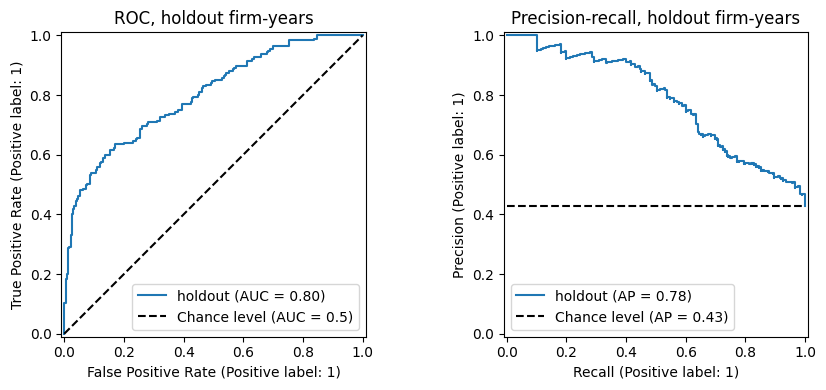

In [27]:
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 4))
RocCurveDisplay.from_predictions(test.SG, test.p_sg, name="holdout", ax=left, plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(test.SG, test.p_sg, name="holdout", ax=right, plot_chance_level=True)
left.set_title("ROC, holdout firm-years"); right.set_title("Precision-recall, holdout firm-years")
fig.tight_layout(); fig.savefig(FIG / "fig_roc_pr.png", dpi=150); plt.show()

Both are quoted: CV is development evidence and may contain model-selection optimism, because the model size was chosen on the same folds; the holdout, one draw of 123 companies, is the independent holdout estimate and has a wide interval.

The BBB/BB boundary is where the difficulty sits. Every candidate in §5 scores about the same there, which suggests the limit is the information in the ratios, not the model choice.

**Where it works, by sector (descriptive).** Out-of-fold calibrated scores on the training companies (three seeds; firm-years, so companies with more statements weigh more; no intervals), and the holdout AUC where a sector has at least 5 holdout firm-years of each class. Every holdout sector result is exploratory: each rests on 5–21 companies. A sector is marked small when it has fewer than 30 training companies, fewer than 10 training firm-years of either class, or fewer than 10 holdout companies.

In [28]:
oof_cal = [platt(oof) for oof, _ in champion_runs]
rows = []
for sector, idx in train.groupby("Sector").indices.items():
    y_s, held = y_train[idx], test[test.Sector == sector]
    minority = int(min(y_s.sum(), len(y_s) - y_s.sum()))
    rows.append({"sector": sector, "companies": train.Name.iloc[idx].nunique(), "firm_years": len(idx), "SG share": y_s.mean(),
                 "AUC (CV)": np.mean([roc_auc_score(y_s, o[idx]) for o in oof_cal]) if minority else np.nan,
                 "mean P(SG) (CV)": np.mean([o[idx].mean() for o in oof_cal]),
                 "holdout companies": held.Name.nunique(),
                 "AUC (holdout, exploratory)": roc_auc_score(held.SG, held.p_sg) if min(held.SG.sum(), len(held) - held.SG.sum()) >= 5 else np.nan,
                 "small": train.Name.iloc[idx].nunique() < 30 or minority < 10 or held.Name.nunique() < 10})
sectors = pd.DataFrame(rows).set_index("sector").sort_values("companies", ascending=False)
print(sectors.round(2).to_string())
keep("sector_diagnostics", sectors.to_dict(orient="index"))
big, rest = sectors[sectors.companies >= 30], sectors[sectors.companies < 30]
print(f"CV AUC across the {len(big)} sectors with at least 30 training companies: {big['AUC (CV)'].min():.2f} to {big['AUC (CV)'].max():.2f};"
      " outside them: " + ", ".join(f"{s} {r['AUC (CV)']:.2f} ({r.companies} companies)" for s, r in rest.iterrows()))
keep("sector_cv_auc_range_30plus", {"sectors": len(big), "min": big["AUC (CV)"].min(), "max": big["AUC (CV)"].max()})

                       companies  firm_years  SG share  AUC (CV)  mean P(SG) (CV)  holdout companies  AUC (holdout, exploratory)  small
sector                                                                                                                                 
Basic Industries              61         202      0.56      0.78             0.53                 18                        0.85  False
Energy                        61         236      0.50      0.78             0.50                 15                        0.77  False
Capital Goods                 60         206      0.38      0.87             0.40                 11                        0.90  False
Consumer Services             60         189      0.62      0.78             0.56                 21                        0.71  False
Technology                    50         150      0.47      0.81             0.43                 20                        0.69  False
Public Utilities              49         191    

## 8. Drivers
SHAP values of the champion on the holdout, in log-odds of a speculative-grade rating. A pillar's share is computed on the summed SHAP of its inputs, so offsetting inputs do not inflate it.

In [29]:
AXIS = "raw log-odds of SG (uncalibrated model)"
PILLARS = {"profitability": ["returnOnAssets", "returnOnCapitalEmployed", "returnOnEquity", "netProfitMargin", "pretaxProfitMargin",
                             "operatingProfitMargin", "ebitPerRevenue", "grossProfitMargin", "roe_negative"],
           "cash flow": ["operatingCashFlowSalesRatio", "freeCashFlowOperatingCashFlowRatio", "ocf_negative"],
           "leverage and coverage": ["debtRatio", "debtEquityRatio", "companyEquityMultiplier", "negative_equity"],
           "liquidity": ["currentRatio", "quickRatio", "cashRatio"],
           "efficiency": ["assetTurnover", "fixedAssetTurnover", "daysOfSalesOutstanding", "payablesTurnover", "payables_zero", "dso_zero"],
           "tax and reporting": ["effectiveTaxRate", "cogs_not_reported"],
           "sector": [f for f in names() if f.startswith("Sector=")]}
FAMILY_PILLAR = {"leverage and coverage": "leverage and coverage", "profitability": "profitability", "earnings quality": "cash flow",
                 "liquidity": "liquidity", "investment": "efficiency", "classic scores": "leverage and coverage", "stability": "stability"}
SECTOR_BASE_PILLAR = {"op_margin_vs_sector": "profitability", "debt_ratio_vs_sector": "leverage and coverage",
                      "coverage_vs_sector": "leverage and coverage", "ocf_sales_vs_sector": "cash flow"}
for c in SPEC["added"]:                                    # the credit features join the pillar of the question they answer
    PILLARS.setdefault(SECTOR_BASE_PILLAR.get(c) or FAMILY_PILLAR[CANDIDATES[c].family], []).append(c)
PILLARS = {k: [f for f in v if f in names()] for k, v in PILLARS.items()}
PILLARS = {k: v for k, v in PILLARS.items() if v}
assert sorted(f for v in PILLARS.values() for f in v) == sorted(names()), "every input belongs to one pillar"


def explain(model, frame, feature_names):
    """shap.Explanation of a fitted pipeline on `frame`, with the preprocessed inputs as data."""
    X = model.named_steps["pre"].transform(frame)
    explainer = shap.TreeExplainer(model.named_steps["model"])
    values = explainer.shap_values(X)
    values = values[1] if isinstance(values, list) else values
    base = np.full(len(X), float(np.ravel(explainer.expected_value)[-1]))
    return shap.Explanation(values=values, base_values=base, data=X, feature_names=feature_names)


def pillar_shares(expl):
    """Share of the mean |summed SHAP| per pillar; summing first stops offsetting inputs inflating a pillar."""
    cols = list(expl.feature_names)
    size = pd.Series({k: np.abs(expl.values[:, [cols.index(f) for f in v]].sum(1)).mean() for k, v in PILLARS.items()})
    return (size / size.sum()).sort_values(ascending=False)


expl = explain(champion, test, names())
sv, X_test, feat_names = expl.values, expl.data, names()
pillar = pillar_shares(expl)
print("share of grouped mean |SHAP|:", pillar.round(3).to_dict())
keep("shap_pillar_share", pillar.to_dict())

top = pd.Series(np.abs(sv).mean(0), index=feat_names).nlargest(8)
reads = {f: spearmanr(X_test[:, feat_names.index(f)], sv[:, feat_names.index(f)]).correlation for f in top.index}
drivers = pd.DataFrame({"mean |SHAP|": top, "rho(value, SHAP)": pd.Series(reads)})
drivers["model reads it as"] = np.where(drivers["rho(value, SHAP)"] > 0.2, "more = riskier",
                                        np.where(drivers["rho(value, SHAP)"] < -0.2, "more = safer", "no single direction"))
print(drivers.round(2).to_string())
keep("shap_top_drivers", drivers.drop(columns="model reads it as").to_dict(orient="index"))


def input_status(model, frame):
    """Per statement ratio and row: 'observed', 'filled' (missing, entered as the training median) or 'clipped' (cut to the training 1st-99th percentile)."""
    pre = model.named_steps["pre"]
    X = pre.named_steps["credit"].transform(frame)[FEATURES + COMPUTED]      # inputs plus the computed credit features
    num = pre.named_steps["columns"].named_transformers_["num"]
    filled = X.isna().to_numpy()
    imputed = num.named_steps["impute"].transform(X)
    lo, hi = num.named_steps["winsor"].lo_.to_numpy(), num.named_steps["winsor"].hi_.to_numpy()
    status = np.where(filled, "filled", np.where((imputed < lo) | (imputed > hi), "clipped", "observed"))
    return pd.DataFrame(status, columns=FEATURES + COMPUTED, index=frame.index)

share of grouped mean |SHAP|: {'profitability': 0.261, 'leverage and coverage': 0.222, 'liquidity': 0.15, 'cash flow': 0.131, 'efficiency': 0.084, 'stability': 0.07, 'sector': 0.042, 'tax and reporting': 0.041}
                             mean |SHAP|  rho(value, SHAP) model reads it as
implied_rate                        0.39              0.82    more = riskier
debtRatio                           0.31              0.93    more = riskier
operatingCashFlowSalesRatio         0.28             -0.76      more = safer
returnOnCapitalEmployed             0.26             -0.96      more = safer
cashRatio                           0.24              0.49    more = riskier
ebitPerRevenue                      0.18             -0.70      more = safer
returnOnAssets                      0.16             -0.93      more = safer
op_margin_vol                       0.16              0.75    more = riskier


**Filled and clipped inputs.** SHAP explains the inputs after preprocessing: a missing ratio enters as the training median and an extreme one at its clip limit, so its explanation describes the stand-in, not the reported number. How often that happens for the top drivers on the holdout:

In [30]:
status = input_status(champion, test)
filled_clipped = pd.DataFrame({"filled": (status == "filled").mean(), "clipped": (status == "clipped").mean()}).loc[[f for f in top.index if f in FEATURES + COMPUTED]]
print(filled_clipped.round(3).to_string())
keep("shap_inputs_filled_or_clipped", filled_clipped.to_dict(orient="index"))

                             filled  clipped
implied_rate                  0.010    0.017
debtRatio                     0.000    0.027
operatingCashFlowSalesRatio   0.000    0.032
returnOnCapitalEmployed       0.000    0.022
cashRatio                     0.020    0.027
ebitPerRevenue                0.000    0.034
returnOnAssets                0.000    0.022
op_margin_vol                 0.301    0.007


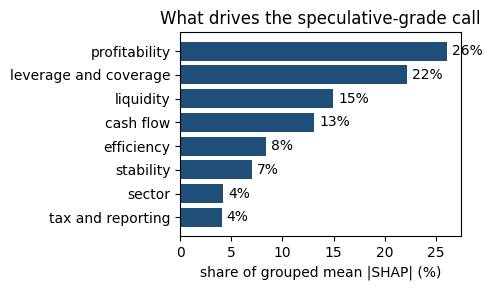

In [31]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.barh(pillar.index[::-1], pillar.values[::-1] * 100, color="#1f4e79")
for y_, v in enumerate(pillar.values[::-1]): ax.text(v * 100 + 0.5, y_, f"{v:.0%}", va="center")
ax.set_xlabel("share of grouped mean |SHAP| (%)"); ax.set_title("What drives the speculative-grade call")
fig.tight_layout(); fig.savefig(FIG / "fig_shap_pillars.png", dpi=150); plt.show()

**Liquidity runs the other way.** Higher liquidity ratios read as riskier. One possible explanation is **market access**: investment-grade companies fund short-term needs through commercial paper and bank lines and run lean working capital, while weaker companies must hold buffers. The data cannot identify the mechanism, so this is a hypothesis. The link is predictive, not causal, so no scenario ever moves liquidity.

The cash ratio is flat, then riskier in the top fifth. Its average SHAP by quintile shows the shape:

In [32]:
k = feat_names.index("cashRatio")
cash_shape = pd.Series(sv[:, k]).groupby(pd.qcut(X_test[:, k], 5, labels=False, duplicates="drop")).mean()
u_shaped = cash_shape.iloc[0] > cash_shape.min() < cash_shape.iloc[-1] and cash_shape.idxmin() not in (cash_shape.index[0], cash_shape.index[-1])
print("mean SHAP of the cash ratio, lowest → highest quintile:", cash_shape.round(2).tolist())
keep("cash_ratio_shap_by_quintile", {"values": cash_shape.tolist(), "u_shaped": u_shaped})

mean SHAP of the cash ratio, lowest → highest quintile: [-0.0, -0.13, -0.15, -0.02, 0.73]


**Global view.** One dot per holdout firm-year, coloured by the input's value; then the mean size per input. Sector is one-hot: one column per sector.

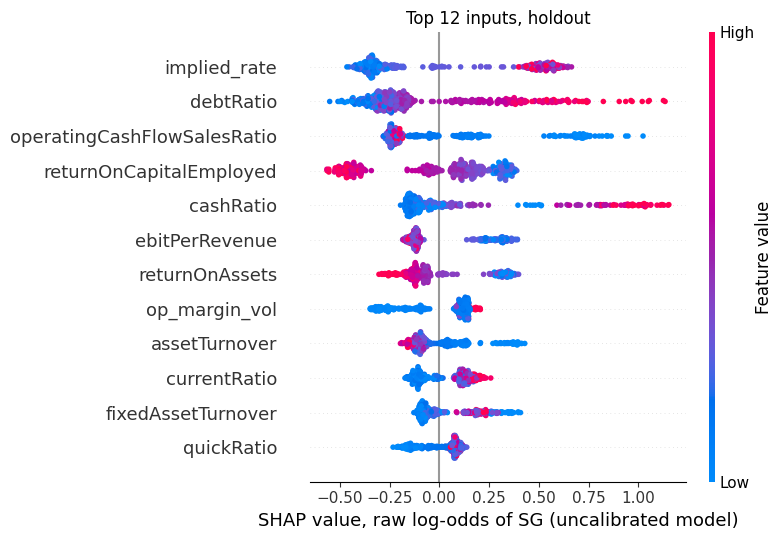

not shown: the other 22 inputs, 19% of the summed mean |SHAP|


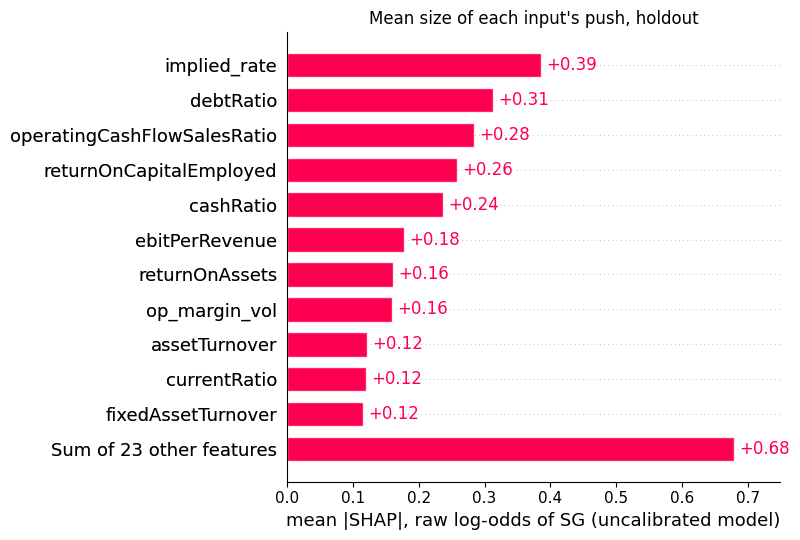

In [33]:
np.random.seed(0)   # shap shuffles dot order with NumPy's global generator
shap.plots.beeswarm(expl, max_display=12, group_remaining_features=False, show=False, plot_size=(8, 5.5))   # a grouped row would be coloured by one input's values
plt.xlabel(f"SHAP value, {AXIS}"); plt.title("Top 12 inputs, holdout")
plt.tight_layout(); plt.savefig(FIG / "fig_shap_beeswarm.png", dpi=150); plt.show()


def not_shown(expl, shown):
    """Inputs left off a top-`shown` plot, and their share of the summed mean |SHAP|."""
    size = np.abs(expl.values).mean(0); rest = np.argsort(-size)[shown:]
    return len(rest), size[rest].sum() / size.sum()


n_rest, rest_share = not_shown(expl, 12)
print(f"not shown: the other {n_rest} inputs, {rest_share:.0%} of the summed mean |SHAP|")

shap.plots.bar(expl, max_display=12, show=False)
plt.xlabel(f"mean |SHAP|, {AXIS}"); plt.title("Mean size of each input's push, holdout")
plt.gcf().set_size_inches(8, 5.5); plt.tight_layout(); plt.savefig(FIG / "fig_shap_bar.png", dpi=150); plt.show()

**Shape of the top four drivers, plus the cash ratio.** Each dot is a holdout firm-year: the input's value against its SHAP. The cash ratio is flat, then riskier in the top fifth. Filled or clipped values sit at the median or at a clip limit; the axis label gives their share.

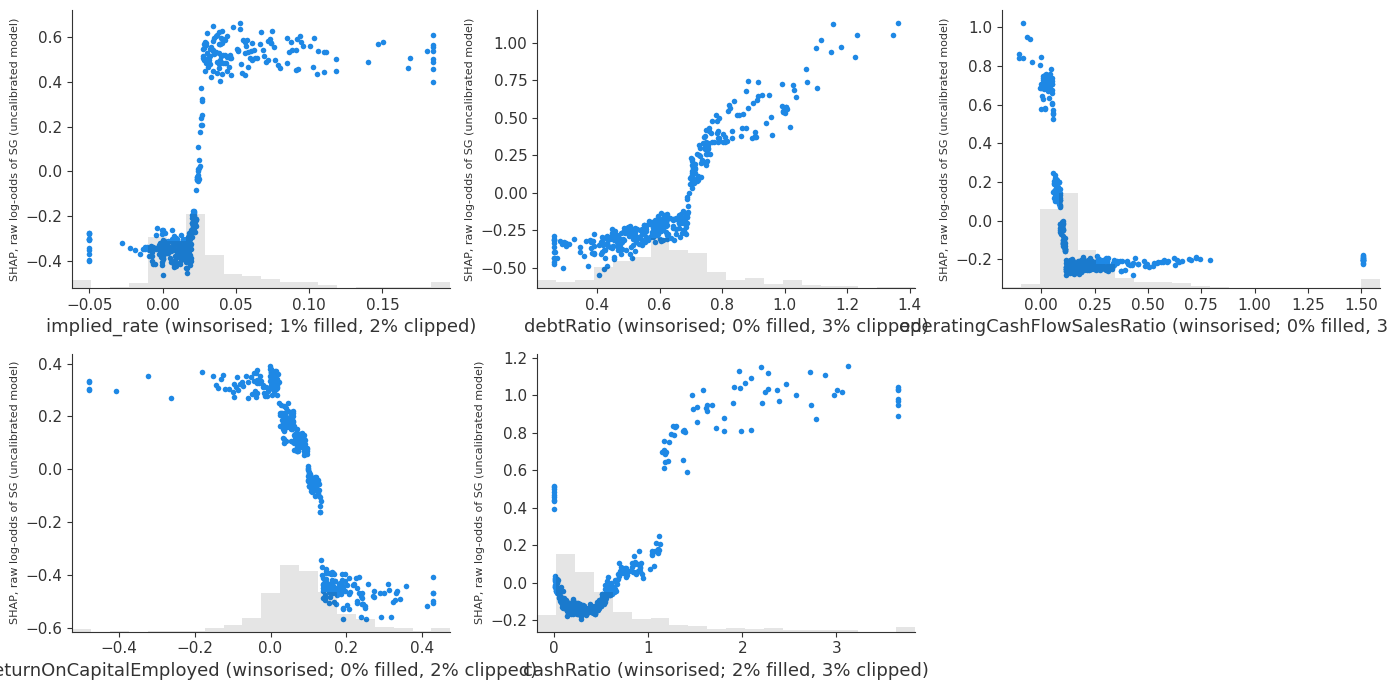

In [34]:
shown = list(top.index[:4]) + ([] if "cashRatio" in top.index[:4] else ["cashRatio"])
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes.flat[-1].set_visible(len(shown) > 5)
for ax, f in zip(axes.flat, shown):
    np.random.seed(0)
    shap.plots.scatter(expl[:, f], ax=ax, show=False)
    ax.set_ylabel(f"SHAP, {AXIS}", fontsize=8); ax.set_xlabel(f"{f} (winsorised; {(status[f] == 'filled').mean():.0%} filled, {(status[f] == 'clipped').mean():.0%} clipped)" if f in status else f"{f} (winsorised)")
fig.tight_layout(); fig.savefig(FIG / "fig_shap_dependence.png", dpi=150); plt.show()

**Three companies, picked by rule:** in each review group (in the 30% review budget; on the screen but outside the budget; below the screen), the company whose calibrated P(SG) is nearest the group median. Each bar is one input's push, from the average score E[f(X)] to the company's score f(x). An input marked [filled] was missing and entered as the training median; [clipped] was cut to the training 1st-99th percentile.

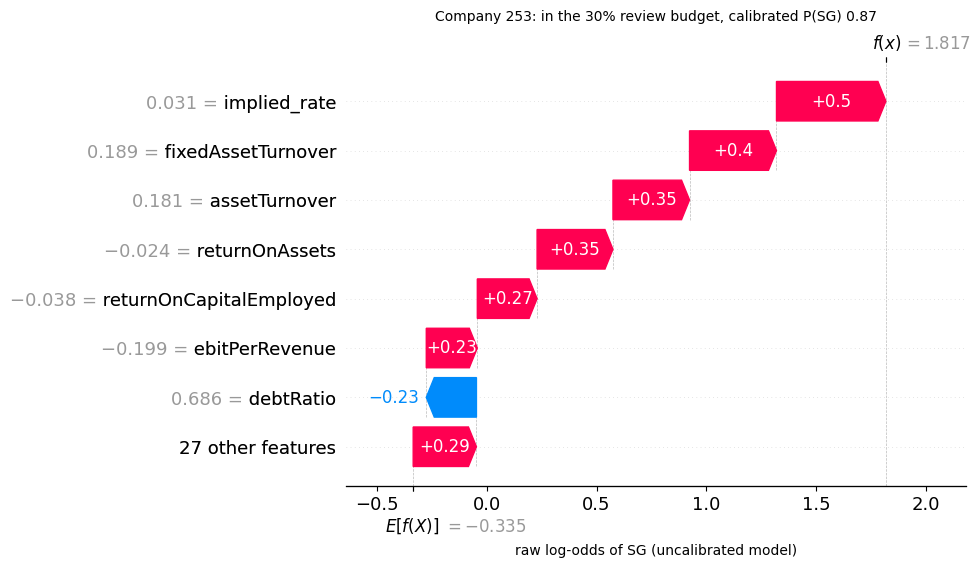

Company 253: pushed up most by implied_rate, fixedAssetTurnover; pulled down most by debtRatio, operatingCashFlowSalesRatio.


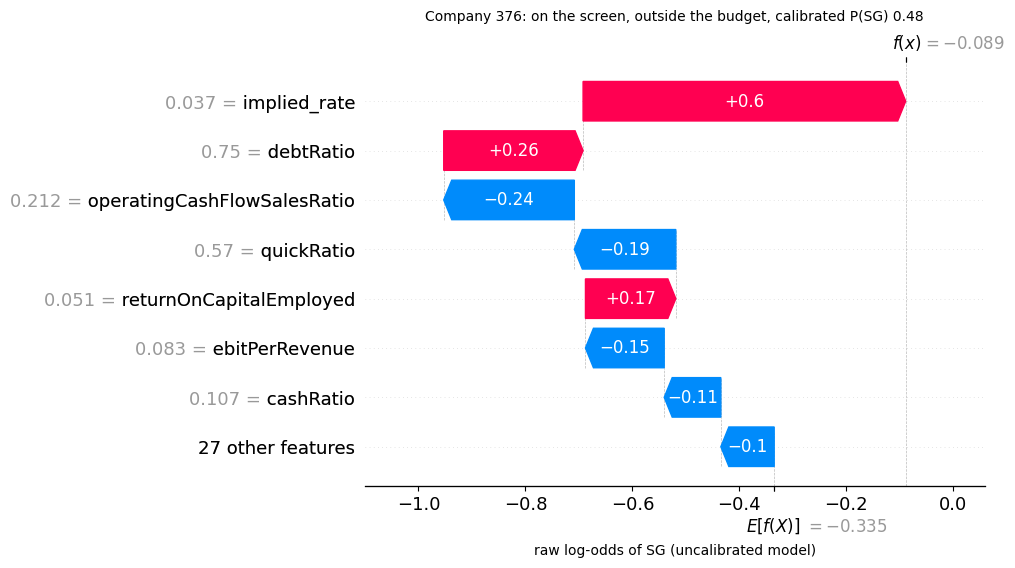

Company 376: pushed up most by implied_rate, debtRatio; pulled down most by operatingCashFlowSalesRatio, quickRatio.


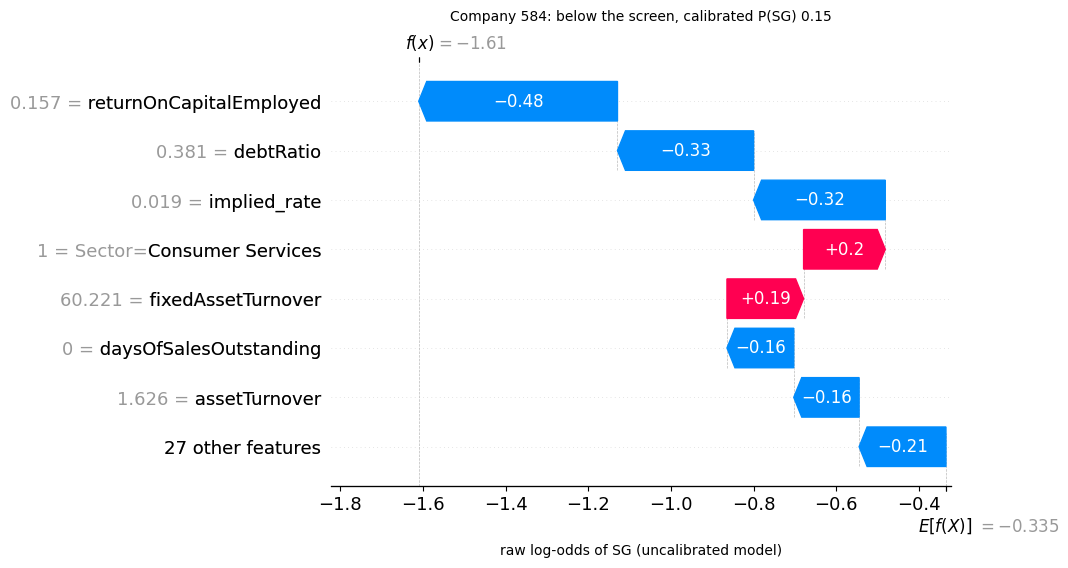

Company 584: pushed up most by Sector=Consumer Services, fixedAssetTurnover; pulled down most by returnOnCapitalEmployed, debtRatio.


In [35]:
def nearest_median(frame, by, score="p_sg"):
    """Per group, the row whose score is nearest the group median (first in order on ties)."""
    return frame.groupby(by)[score].apply(lambda s: (s - s.median()).abs().sort_values(kind="stable").index[0])


def top_contributors(expl, row, k=3):
    """The k inputs with the largest |SHAP| for one row, signed."""
    contrib = pd.Series(expl.values[row], index=expl.feature_names); return contrib.reindex(contrib.abs().nlargest(k).index)


def push_pull(expl, row, k=2):
    """One plain line: the inputs that pushed the score up most and pulled it down most."""
    contrib = pd.Series(expl.values[row], index=expl.feature_names)
    up, down = contrib.nlargest(k), contrib.nsmallest(k)
    return f"pushed up most by {', '.join(up.index[up > 0]) or 'nothing'}; pulled down most by {', '.join(down.index[down < 0]) or 'nothing'}."


picks = nearest_median(portfolio, "group")
SLUG = {"in the 30% review budget": "budget", "on the screen, outside the budget": "screen_outside_budget", "below the screen": "below_screen"}
examples = []
for group, slug in SLUG.items():
    if group not in picks.index: continue
    idx = picks[group]; row, company, marks = test.index.get_loc(idx), portfolio.loc[idx], status.loc[idx]
    labels = [f"{n} [{marks[n]}]" if n in marks.index and marks[n] != "observed" else n for n in expl.feature_names]
    one = shap.Explanation(values=expl.values[row], base_values=expl.base_values[row], data=expl.data[row], feature_names=labels)
    shap.plots.waterfall(one, max_display=8, show=False)
    plt.gcf().axes[0].set_xlabel(AXIS, labelpad=22); plt.title(f"{company.Name}: {group}, calibrated P(SG) {company.p_sg:.2f}", fontsize=10, pad=30)
    plt.savefig(FIG / f"fig_shap_local_{slug}.png", dpi=150, bbox_inches="tight"); plt.show()   # shap's own size: resizing after drawing misplaces the value labels
    print(f"{company.Name}: {push_pull(expl, row)}")
    examples.append({"company": company.Name, "group": group, "p_sg": company.p_sg, "top3_shap": top_contributors(expl, row).to_dict(),
                     "filled_or_clipped": {n: marks[n] for n in marks.index if marks[n] != "observed"}})
keep("shap_local_examples", examples)

**Slide versions.** The same SHAP values in the library's standard style, with readable input names, at slide resolution (`figures/slides/`): the global beeswarm on the holdout (the ten strongest inputs, no grouped row: shap would colour it by one input's values; the footnote gives the share of the push left off), and the waterfalls of Company 509 (the worked example of §6) and Company 280 (a speculative-grade example), 12 rows each so that debt ratio and operating cash flow / sales stay in view. Drawn at shap's own size, because resizing a waterfall after drawing misplaces its value labels.

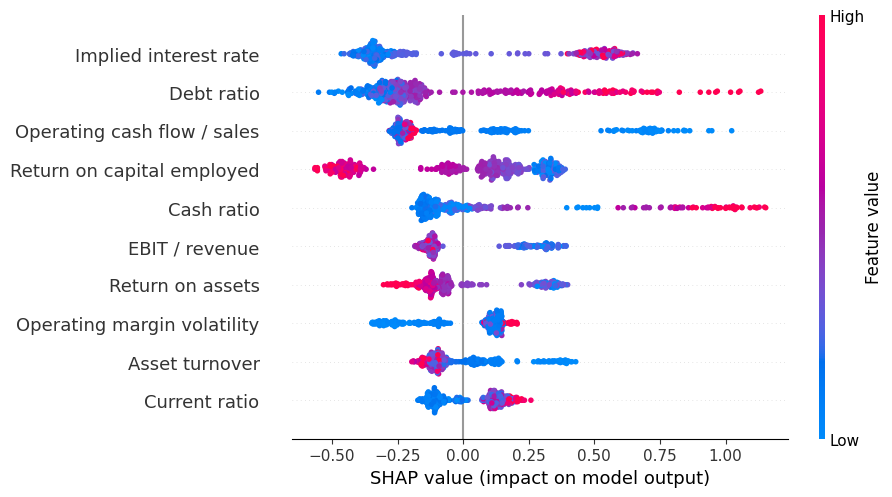

slide footnote: the other 24 inputs carry 26% of the total push (summed mean |SHAP|)


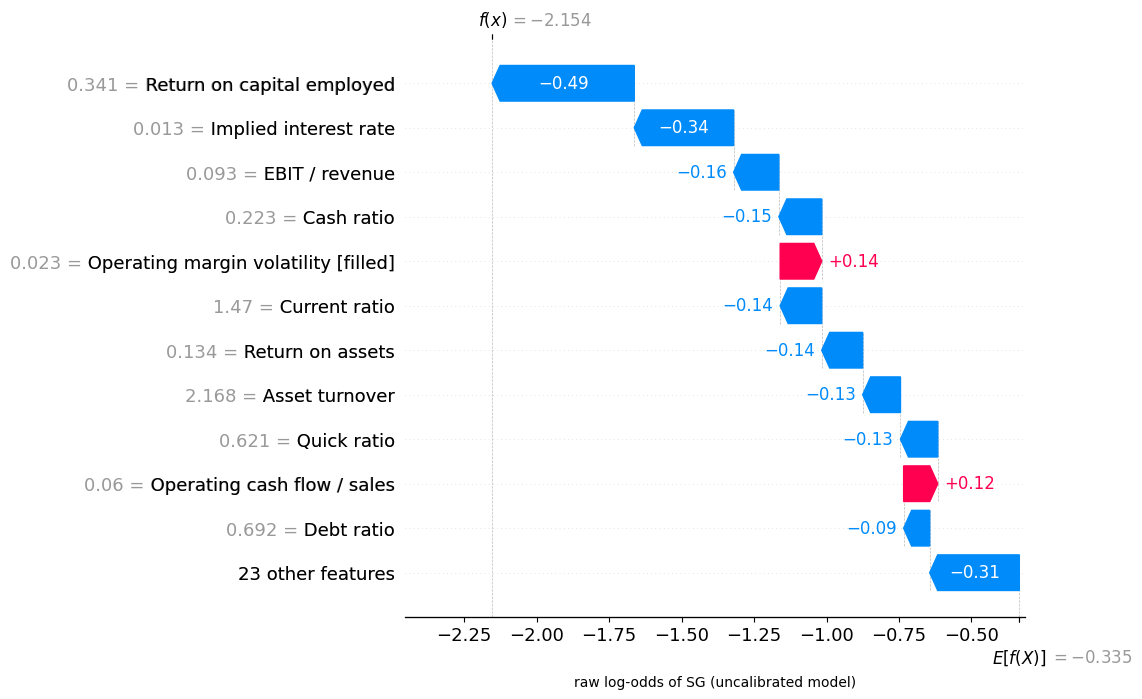

Company 509: rated BBB, Capital Goods, 2012 | raw score -2.1538 | calibrated P(SG) 0.093 | pushed up most by op_margin_vol, operatingCashFlowSalesRatio; pulled down most by returnOnCapitalEmployed, implied_rate.
   in view: {'debtRatio': -0.09, 'operatingCashFlowSalesRatio': 0.118}


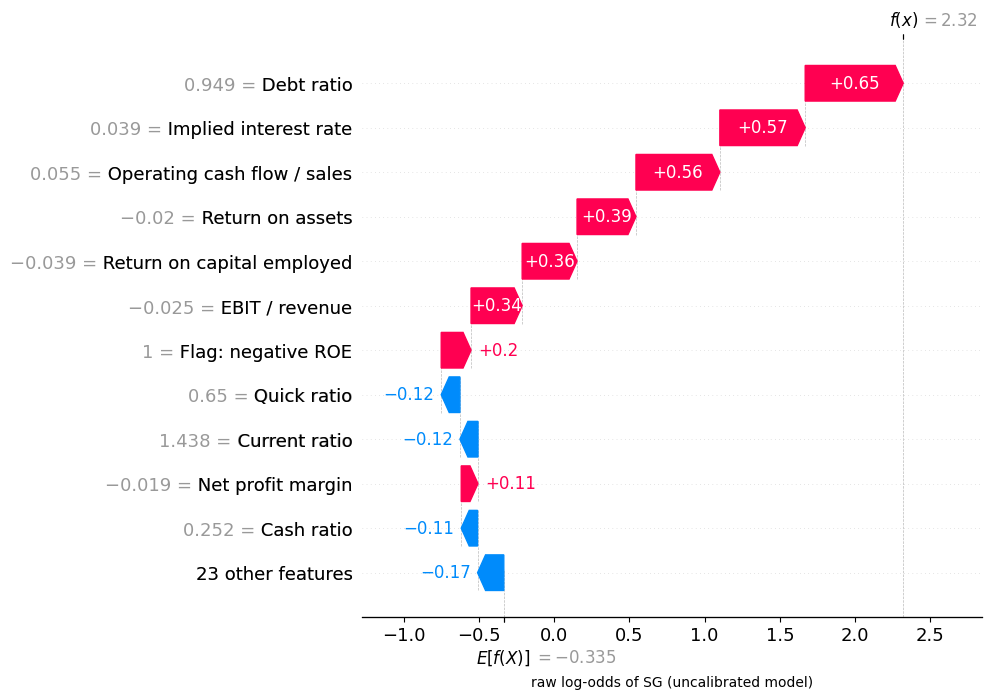

Company 280: rated B, Capital Goods, 2016 | raw score 2.3199 | calibrated P(SG) 0.922 | pushed up most by debtRatio, implied_rate; pulled down most by quickRatio, currentRatio.
   in view: {'debtRatio': 0.651, 'operatingCashFlowSalesRatio': 0.557}


In [36]:
SLIDES = FIG / "slides"; SLIDES.mkdir(exist_ok=True)
READABLE = {
    "currentRatio": "Current ratio", "quickRatio": "Quick ratio", "cashRatio": "Cash ratio", "daysOfSalesOutstanding": "Days sales outstanding",
    "netProfitMargin": "Net profit margin", "pretaxProfitMargin": "Pre-tax margin", "grossProfitMargin": "Gross margin",
    "operatingProfitMargin": "Operating margin", "returnOnAssets": "Return on assets", "returnOnCapitalEmployed": "Return on capital employed",
    "returnOnEquity": "Return on equity", "assetTurnover": "Asset turnover", "fixedAssetTurnover": "Fixed asset turnover",
    "debtEquityRatio": "Debt / equity", "debtRatio": "Debt ratio", "effectiveTaxRate": "Effective tax rate",
    "freeCashFlowOperatingCashFlowRatio": "Free cash flow / operating cash flow", "companyEquityMultiplier": "Equity multiplier",
    "ebitPerRevenue": "EBIT / revenue", "operatingCashFlowSalesRatio": "Operating cash flow / sales", "payablesTurnover": "Payables turnover",
    "roe_negative": "Flag: negative ROE", "negative_equity": "Flag: negative equity", "ocf_negative": "Flag: negative operating cash flow",
    "cogs_not_reported": "Flag: COGS not reported", "payables_zero": "Flag: payables zero", "dso_zero": "Flag: DSO zero"}
READABLE.update({c: CANDIDATES[c].label for c in CANDIDATES})
readable = lambda n: READABLE.get(n, n.replace("Sector=", "Sector: "))
slide_expl = shap.Explanation(values=expl.values, base_values=expl.base_values, data=expl.data,
                              feature_names=[readable(n) for n in expl.feature_names])

np.random.seed(0)   # shap shuffles dot order with NumPy's global generator
shap.plots.beeswarm(slide_expl, max_display=10, group_remaining_features=False, show=False)   # no grouped row: shap colours it by one input's values
plt.savefig(SLIDES / "shap_global_beeswarm.png", dpi=300, bbox_inches="tight"); plt.show()
n_rest, rest_share = not_shown(expl, 10)
print(f"slide footnote: the other {n_rest} inputs carry {rest_share:.0%} of the total push (summed mean |SHAP|)")
keep("shap_slide_not_shown", {"shown": 10, "inputs_not_shown": n_rest, "share_of_summed_mean_abs_shap": rest_share})

for name in ["Company 509", "Company 280"]:
    idx = portfolio.index[portfolio.Name == name][0]             # latest statement of that holdout company
    row, marks, company = test.index.get_loc(idx), status.loc[idx], portfolio.loc[idx]
    labels = [f"{readable(n)} [{marks[n]}]" if n in marks.index and marks[n] != "observed" else readable(n) for n in expl.feature_names]
    one = shap.Explanation(values=expl.values[row], base_values=expl.base_values[row], data=np.round(expl.data[row], 3), feature_names=labels)
    assert np.isclose(one.values.sum() + one.base_values, np.log(company.p_raw / (1 - company.p_raw)), atol=1e-6)   # adds up to its raw score
    shap.plots.waterfall(one, max_display=12, show=False)   # 12 rows: keeps debt ratio and operating cash flow / sales in view
    plt.gcf().axes[0].set_xlabel(AXIS, labelpad=22)
    plt.savefig(SLIDES / f"shap_local_{name.split()[-1]}.png", dpi=300, bbox_inches="tight"); plt.show()
    print(f"{name}: rated {company.Rating}, {company.Sector}, {company.Date.year} | raw score {one.values.sum() + one.base_values:.4f} "
          f"| calibrated P(SG) {company.p_sg:.3f} | {push_pull(expl, row)}")
    shown = pd.Series(one.values, index=expl.feature_names).abs().nlargest(11).index
    print("   in view:", {f: round(float(one.values[expl.feature_names.index(f)]), 3) for f in ["debtRatio", "operatingCashFlowSalesRatio"] if f in shown})

## 9. Out of time: the 2015–16 Energy shock (exploratory)
The model is trained on ratings dated up to 2014 (mostly 2012–14), before the oil-price crash reached the financials, and scored on ratings dated 2015–16. The split is by date, so holdout companies are included; no choice is made here. This is a nowcast: 2016 statements already show the damage. The test is whether the ranking stays right through the shock.

The lead number is for **new companies**, never seen up to 2014. Companies seen before are scored on statements of firms the model already knows. The new-company samples are small, so sizes are printed next to each AUC.

**Read it as exploratory and as a historical diagnostic.** The samples are small, and the inputs, the monotone constraints and the model size were chosen with all years in view, so this is not a full simulation of the model that would have been built in 2014.

In [37]:
before = data[data.year <= 2014].reset_index(drop=True)
after = data[data.year >= 2015].reset_index(drop=True)
oot_runs = oof_runs(lgbm, before)
oot_platt = Platt().fit(oot_runs, before.SG.values)
oot_model = lgbm().fit(before, before.SG)
after["p_sg"] = oot_platt(oot_model.predict_proba(after)[:, 1])
before["p_sg"] = oot_platt(np.mean([oof for oof, _ in oot_runs], axis=0))
after["new_company"] = ~after.Name.isin(set(before.Name))

energy = after[after.Sector == "Energy"]
new = energy.new_company
slices = {"Energy, new companies, 2015-16": energy[new], "Energy, new companies, 2015": energy[new & (energy.year == 2015)],
          "Energy, new companies, 2016": energy[new & (energy.year == 2016)], "Energy 2015": energy[energy.year == 2015],
          "Energy 2016": energy[energy.year == 2016], "all sectors, new companies": after[after.new_company]}
oot = pd.DataFrame({k: {"AUC": roc_auc_score(e.SG, e.p_sg), "companies": e.Name.nunique(), "firm_years": len(e),
                        "SG_firm_years": int(e.SG.sum())} for k, e in slices.items()}).T
print(oot.round(2).to_string())
ranking = oot.AUC.to_dict()
keep("out_of_time", oot.to_dict(orient="index"))
keep("out_of_time_auc", ranking)

                                 AUC  companies  firm_years  SG_firm_years
Energy, new companies, 2015-16  0.76       19.0        33.0           24.0
Energy, new companies, 2015     0.63       10.0        12.0            7.0
Energy, new companies, 2016     0.88       16.0        21.0           17.0
Energy 2015                     0.72       48.0        61.0           27.0
Energy 2016                     0.87       55.0        74.0           49.0
all sectors, new companies      0.83      121.0       185.0          109.0


Energy, SG share of firm-years, actual vs mean calibrated P(SG) (2012–14 scored out-of-fold):
       actual  predicted  firm_years
year                               
2012    0.38       0.32          47
2013    0.39       0.41          41
2014    0.40       0.37          55
2015    0.44       0.48          61
2016    0.66       0.71          74


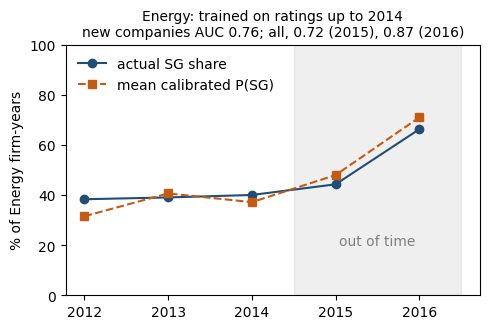

In [38]:
by_year = pd.concat([before, after])
by_year = by_year[(by_year.Sector == "Energy") & (by_year.year >= 2012)].groupby("year").agg(
    actual=("SG", "mean"), predicted=("p_sg", "mean"), firm_years=("SG", "size"))
print("Energy, SG share of firm-years, actual vs mean calibrated P(SG) (2012–14 scored out-of-fold):\n", by_year.round(2).to_string())
keep("energy_by_year", by_year.to_dict(orient="index"))

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(by_year.index, by_year.actual * 100, "o-", color="#1f4e79", label="actual SG share")
ax.plot(by_year.index, by_year.predicted * 100, "s--", color="#c55a11", label="mean calibrated P(SG)")
ax.axvspan(2014.5, 2016.5, color="grey", alpha=0.12); ax.text(2015.5, 20, "out of time", ha="center", color="grey")
ax.set_xticks(by_year.index); ax.set_ylim(0, 100); ax.set_ylabel("% of Energy firm-years")
ax.set_title(f"Energy: trained on ratings up to 2014\nnew companies AUC {ranking['Energy, new companies, 2015-16']:.2f}; all, {ranking['Energy 2015']:.2f} (2015), {ranking['Energy 2016']:.2f} (2016)", fontsize=10)
ax.legend(frameon=False, loc="upper left"); fig.tight_layout(); fig.savefig(FIG / "fig_energy_out_of_time.png", dpi=150); plt.show()

**Same-agency illustration.** Energy companies rated IG by an agency before the crash, and rated again by the **same** agency in 2016: those it moved to SG against those it kept IG. Small, so an illustration only.

In [39]:
scored = pd.concat([before, after])
energy_rows = scored[scored.Sector == "Energy"].sort_values("Date")
pre = energy_rows[energy_rows.year <= 2014].groupby(["Name", "agency"]).tail(1)
post = energy_rows[energy_rows.year == 2016].groupby(["Name", "agency"]).tail(1)
pairs = pre.merge(post, on=["Name", "agency"], suffixes=("_pre", "_2016"))
pairs = pairs[pairs.SG_pre == 0]
illus = pairs.groupby("SG_2016").agg(pairs=("Name", "size"), companies=("Name", "nunique"),
                                     median_psg_pre=("p_sg_pre", "median"), median_psg_2016=("p_sg_2016", "median"))
illus.index = illus.index.map({0: "stayed IG", 1: "moved to SG"})
print(illus.round(2).to_string())
keep("energy_same_agency_illustration", illus.to_dict(orient="index"))

             pairs  companies  median_psg_pre  median_psg_2016
SG_2016                                                       
stayed IG       13         13            0.25             0.53
moved to SG      6          6            0.36             0.71


## 10. The rare-event view: an early signal of IG → SG migration (point-in-time, exploratory)
Unit: two consecutive ratings of a company by the same agency, the first one IG. A "mover" is rated SG next time.
Each first statement is scored by a model trained **only on rows dated before that year**, from other companies. Only rankings are used, so no probability is shown here. All companies are used, holdout included; no choice is made here.

The caveat of §9 applies: each model is refitted on earlier years only, but the design was chosen with all years in view, so this is a historical diagnostic.

In [40]:
BLUE, ORANGE, SURFACE, INK, INK2, MUTED, GRID = "#2a78d6", "#eb6834", "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"


def style(ax, xlabel, ylabel):
    """House style for the cyber charts: surface, hairline grid, muted axes, no top/right spines."""
    ax.set_facecolor(SURFACE); ax.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color(MUTED)
    ax.tick_params(colors=INK2, labelsize=9); ax.set_xlabel(xlabel, color=INK2, fontsize=9); ax.set_ylabel(ylabel, color=INK2, fontsize=9)

In [41]:
seq = data.sort_values(["Name", "agency", "Date"])
seq["next_SG"] = seq.groupby(["Name", "agency"]).SG.shift(-1)
mig = seq[(seq.SG == 0) & seq.next_SG.notna()].copy()
mig["mover"] = mig.next_SG.astype(int)
def point_in_time_scores(pairs, history, make_model, min_history=200):
    """Score each pair's first statement with a model trained only on earlier years and on other companies."""
    score = pd.Series(np.nan, index=pairs.index)
    for yr in sorted(pairs.year.unique()):
        rows = pairs[pairs.year == yr]
        groups = np.random.default_rng(int(yr)).permutation(rows.Name.unique())
        for g in range(5):
            held = set(groups[g::5])
            past = history[(history.year < yr) & ~history.Name.isin(held)]
            if not held or len(past) < min_history: continue      # too little earlier history
            idx = rows.index[rows.Name.isin(held)]
            score[idx] = make_model().fit(past, past.SG).predict_proba(pairs.loc[idx])[:, 1]
    return score


mig["score"] = point_in_time_scores(mig, data, lgbm)

signal = {}
for label, d in [("all IG", mig), ("BBB only", mig[mig.Rating == "BBB"])]:
    d = d.dropna(subset=["score"])
    ci = company_ci(lambda f: roc_auc_score(f.mover, f.score), d)
    signal[label] = {"pairs": len(d), "companies": d.Name.nunique(), "movers": int(d.mover.sum()),
                     "auc": roc_auc_score(d.mover, d.score), "auc_ci": ci,
                     "median_days_to_next_rating": (seq.groupby(["Name", "agency"]).Date.shift(-1)[d.index] - d.Date).dt.days.median()}
    print(f"{label:8s}: {len(d)} pairs, {int(d.mover.sum())} movers | AUC {signal[label]['auc']:.2f} [{ci[0]:.2f}, {ci[1]:.2f}]")
print(f"pairs left unscored (too little earlier history): {int(mig.score.isna().sum())}")
keep("migration_point_in_time", signal)

all IG  : 453 pairs, 27 movers | AUC 0.68 [0.56, 0.79]


BBB only: 226 pairs, 24 movers | AUC 0.64 [0.50, 0.77]
pairs left unscored (too little earlier history): 164


**Reading:** a modest early signal, up to about a year ahead: IG companies that later cross to SG already rank riskier on their last IG statements. Within BBB alone the signal is weaker and its interval reaches 0.5 (AUC 0.64 [0.50, 0.77]): no clear signal there. It is not a forecast, and statement timing is not verified.

**Judged as a rare event.** Crossing from IG to SG between two ratings is rare here (the base rate is printed below). That is the shape of the team's problem: only a few cyber incidents matter for credit, as only a few companies default. So it is judged with rare-event measures, not accuracy: PR-AUC against the base rate (a random ranking scores the base rate), and how many movers a review of the riskiest-scored statements would catch, with the lift over the base rate. Intervals resample companies. Exploratory: few movers.

all IG: 27 movers in 453 pairs, base rate 6.0% | PR-AUC 0.148 [0.080, 0.254] (no skill 0.060, so 2.5x)
pairs reviewed movers caught    count precision lift
           10%           30%  8 of 27     17.8% 3.0x
           20%           44% 12 of 27     13.2% 2.2x
           30%           63% 17 of 27     12.5% 2.1x


BBB only: 24 movers in 226 pairs, base rate 10.6% | PR-AUC 0.197 [0.112, 0.328] (no skill 0.106, so 1.9x)
pairs reviewed movers caught    count precision lift
           10%           17%  4 of 24     17.4% 1.6x
           20%           42% 10 of 24     22.2% 2.1x
           30%           50% 12 of 24     17.6% 1.7x


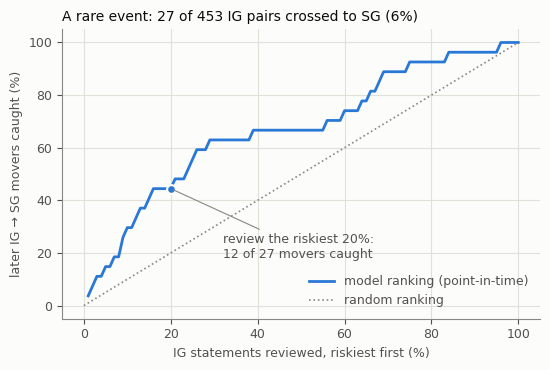

In [42]:
scored_m = mig.dropna(subset=["score"])
rare = {}
for label, d in [("all IG", scored_m), ("BBB only", scored_m[scored_m.Rating == "BBB"])]:
    base = d.mover.mean()
    ap_m = average_precision_score(d.mover, d.score)
    ap_ci = company_ci(lambda f: average_precision_score(f.mover, f.score), d)
    caps = []
    for share in [0.1, 0.2, 0.3]:
        top = d.nlargest(round(share * len(d)), "score")
        caps.append({"pairs reviewed": share, "movers caught": top.mover.sum() / d.mover.sum(),
                     "count": f"{int(top.mover.sum())} of {int(d.mover.sum())}", "precision": top.mover.mean(), "lift": top.mover.mean() / base})
    rare[label] = {"pairs": len(d), "movers": int(d.mover.sum()), "base_rate": base, "prauc": ap_m, "prauc_ci": ap_ci, "capture": caps}
    print(f"{label}: {int(d.mover.sum())} movers in {len(d)} pairs, base rate {base:.1%} | PR-AUC {ap_m:.3f} [{ap_ci[0]:.3f}, {ap_ci[1]:.3f}]"
          f" (no skill {base:.3f}, so {ap_m / base:.1f}x)")
    print(pd.DataFrame(caps).to_string(index=False, formatters={"pairs reviewed": "{:.0%}".format, "movers caught": "{:.0%}".format,
                                                                  "precision": "{:.1%}".format, "lift": "{:.1f}x".format}))
keep("migration_rare_event", rare)

shares_m = np.linspace(0.01, 1, 100)
caught_m = [scored_m.nlargest(round(s * len(scored_m)), "score").mover.sum() / scored_m.mover.sum() * 100 for s in shares_m]
c20 = rare["all IG"]["capture"][1]
fig, ax = plt.subplots(figsize=(5.6, 3.8), facecolor=SURFACE)
ax.plot(shares_m * 100, caught_m, color=BLUE, lw=2, label="model ranking (point-in-time)")
ax.plot([0, 100], [0, 100], ls=":", color=MUTED, lw=1.2, label="random ranking")
ax.scatter([20], [c20["movers caught"] * 100], s=40, color=BLUE, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.annotate(f"review the riskiest 20%:\n{c20['count']} movers caught", (20, c20["movers caught"] * 100), xytext=(32, 18),
            color=INK2, fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
style(ax, "IG statements reviewed, riskiest first (%)", "later IG → SG movers caught (%)")
ax.set_title(f"A rare event: {rare['all IG']['movers']} of {rare['all IG']['pairs']} IG pairs crossed to SG ({rare['all IG']['base_rate']:.0%})",
             loc="left", fontsize=10, color=INK)
ax.legend(frameon=False, loc="lower right", fontsize=9, labelcolor=INK2)
fig.tight_layout(); fig.savefig(FIG / "fig_migration_capture.png", dpi=150, facecolor=SURFACE); plt.show()

## 11. Cyber headroom
**Headroom** is the incident cost, as a share of annual revenue, that would put a firm on the review list. It is partly the firm's distance to the screen and partly how fast a cost erodes it (margin cushion, asset turnover, leverage). It measures capacity to absorb an incident, not cyber exposure: the model has no cyber data.

The cost is charged to one year's statements, as if the agency did not look through it. For a true one-off the effect on a rating would be smaller.

What the shock does: margins fall by the cost; net margin and operating cash flow by the after-tax cost (no tax shield beyond the firm's pre-tax profit); ROA, ROCE and ROE by the cost over their own denominators; FCF/OCF falls with cash flow; the firm borrows the after-tax cost. The two credit features of 03 are held at today's value: the implied interest rate (the shock adds no interest on the new debt and no spread widening) and the operating-margin volatility (the company's history), so the shock understates those channels. Debt/equity and the equity multiplier are not model inputs (03 found they add nothing beyond the debt ratio). Liquidity and sector are untouched.

**A model-based scenario, not a downgrade forecast.** The intervals below resample companies only: they leave out the uncertainty in the fitted model, in the accounting assumptions, and in how an incident's cost lands (lost sales, remediation, fines and insurance recoveries hit the statements differently). A sensitivity table at the end of this section varies the main assumptions.

In [43]:
# TAX, MAX_COST, fit_reference, assets_over_capital_employed and incident_shock live in cyber_credit/shock.py (shared with the app)


def crosses_at(score, frame, threshold, ref, cost, debt_funded=True, tax=TAX):
    """Whether each row's score reaches the threshold at exactly this cost."""
    return score(incident_shock(frame, cost, ref, debt_funded, tax)) >= threshold


def headroom(score, frame, threshold, ref, tol=1e-6, debt_funded=True, tax=TAX):
    """Smallest cost at which the shocked score reaches the threshold, by bisection: 0 if already there, inf if never."""
    out = np.full(len(frame), np.nan)
    out[score(frame) >= threshold] = 0.0
    out[np.isnan(out) & ~crosses_at(score, frame, threshold, ref, MAX_COST, debt_funded, tax)] = np.inf
    todo = np.flatnonzero(np.isnan(out))
    lo, hi = np.zeros(len(todo)), np.full(len(todo), MAX_COST)
    while (hi - lo).max(initial=0) > tol:
        mid = (lo + hi) / 2
        crossed = crosses_at(score, frame.iloc[todo], threshold, ref, mid, debt_funded, tax)
        hi, lo = np.where(crossed, mid, hi), np.where(crossed, lo, mid)
    out[todo] = hi
    return pd.Series(out, index=frame.index, name="headroom")


def monotone_violations(score, frame, ref, debt_funded=True):
    """Rows whose score ever falls as the cost grows (zero by construction; a guard)."""
    p = np.column_stack([score(incident_shock(frame, c, ref, debt_funded)) for c in np.linspace(0, MAX_COST, 61)])
    return int((np.diff(p, axis=1) < -1e-9).any(axis=1).sum())


def outage_days(cost, gross_margin, uplift=1.0):
    """Headroom as days of full outage: daily revenue x margin lost, margin kept within 5-100%."""
    return np.asarray(cost, dtype=float) * 365 / np.clip(np.asarray(gross_margin, dtype=float) * uplift, 0.05, 1.0)


def company_bootstrap(values, stat, n=2000, seed=0):
    """Point estimate and 95% interval of stat, resampling companies (one value per company)."""
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    draws = [stat(values[rng.integers(0, len(values), len(values))]) for _ in range(n)]
    return float(stat(values)), float(np.percentile(draws, 2.5)), float(np.percentile(draws, 97.5))


def exact_share(crossed):
    """Companies crossing: count, share and exact (Clopper-Pearson) 95% interval. One value per company, so a binomial interval
    applies (independence across companies is an assumption); unlike a bootstrap, it stays informative when none cross."""
    k, n = int(np.sum(crossed)), len(crossed)
    ci = binomtest(k, n).proportion_ci(confidence_level=0.95, method="exact")
    return k, n, k / n, (float(ci.low), float(ci.high))

**Anchors.** Reported profit impact over annual revenue for six well-known incidents (checked against filings). They are severe, widely reported cases: in Cyentia's IRIS 2022, two-thirds of reported cyber losses were below 1% of revenue, and for firms with USD 1–10bn revenue the typical loss was about 0.01–0.08% of revenue. So 1–2% is a tail scenario for firms of this size. The M&S figure is an estimate, gross of insurance.

In [44]:
ANCHORS = pd.DataFrame([
    ("Norsk Hydro", 2019, 0.0040, "NOK 550-650m H1 2019 / NOK 149.8bn revenue", "gross"),
    ("Maersk", 2017, 0.0081, "USD 200-300m / USD 30.9bn revenue", "not stated"),
    ("MGM Resorts", 2023, 0.0068, "~USD 110m / USD 16.2bn revenue", "gross"),
    ("UnitedHealth", 2024, 0.0077, "USD 3.07bn (10-K) / USD 400.3bn revenue", "as reported"),
    ("Merck", 2017, 0.0115, "USD 177m lost-sales profit + USD 285m net costs / USD 40.1bn revenue", "partly net"),
    ("Marks & Spencer", 2025, 0.0217, "~GBP 300m operating profit / GBP 13.8bn revenue", "estimated, gross of insurance"),
], columns=["incident", "year", "share_of_revenue", "basis", "insurance"])
# sources: Hydro Q2 2019 results; Maersk Q2 2017 interim; MGM 8-K 5 Oct 2023; UnitedHealth 2024 10-K; Merck 2017 10-K;
# M&S FY2024/25 results (FCA RNS 5662462)

Checks on the shock: it is row-wise, adds no missing values, changes nothing at a cost of 0, gives no tax shield beyond pre-tax profit, and never lowers the score as the cost grows (by construction; the check is a guard).

In [45]:
ref = fit_reference(train)   # training-set constants only
heads = latest(test)         # one row per company: its latest statement

pd.testing.assert_frame_equal(incident_shock(heads, 0.0, ref), heads, check_dtype=False)
assert not (incident_shock(heads, 0.05, ref).isna() & heads.notna()).any().any()
costs = np.linspace(0, 0.2, len(heads))
by_row = pd.concat([incident_shock(heads.iloc[[i]], costs[i], ref) for i in range(len(heads))])
pd.testing.assert_frame_equal(incident_shock(heads, costs, ref), by_row)

taxed = heads.head(3).assign(pretaxProfitMargin=[0.20, 0.02, -0.05])
drop = taxed.netProfitMargin - incident_shock(taxed, 0.10, ref).netProfitMargin
assert np.allclose(drop, [0.10 * (1 - TAX), 0.10 - TAX * 0.02, 0.10])   # full, partial, no shield

assert monotone_violations(p_sg, heads, ref) == 0 and monotone_violations(p_sg, heads, ref, debt_funded=False) == 0
print("shock checks passed")

shock checks passed


Headroom for companies below the screen today, to two lines: the review screen (its calibrated P(SG) is printed) and the model's classification at calibrated P(SG) ≥ 0.5 (not an agency decision). Companies the agencies already rate speculative grade are reported separately. Crossings at an anchor are computed at the exact anchor cost and reported as counts of companies with an exact (Clopper-Pearson) 95% interval: one row per company removes repeated-company dependence (independence across companies is an assumption), and the interval stays informative when none cross (a bootstrap would return [0%, 0%]).

In [46]:
below = heads[p_sg(heads) < SCREEN]
rated_ig = (below.SG == 0).to_numpy()
to_screen = headroom(p_sg, below, SCREEN, ref)
to_sg_call = headroom(p_sg, below, 0.5, ref)
MS = float(ANCHORS.set_index("incident").share_of_revenue["Marks & Spencer"])
ms_screen = crosses_at(p_sg, below, SCREEN, ref, MS)
ms_call = crosses_at(p_sg, below, 0.5, ref, MS)
assert ((to_screen <= MS) <= ms_screen).all() and (ms_screen <= (to_screen <= MS + 1e-6)).all()   # bisection agrees with the exact check


def describe(h, crossed, label):
    """Median headroom (company-bootstrap 95% interval) and companies crossing at an M&S-scale hit (count, exact 95% interval)."""
    if len(h) == 0:
        print(f"{label}: no companies"); return None
    med, lo, hi = company_bootstrap(h, np.median)
    k, n, share, (s_lo, s_hi) = exact_share(crossed)
    print(f"{label} ({n} companies): median {med:.1%} [{lo:.1%}, {hi:.1%}]; "
          f"at an M&S-scale 2.2% hit {k} of {n} cross ({share:.0%}, exact 95% interval {s_lo:.0%}-{s_hi:.0%})")
    return {"companies": n, "median": med, "median_ci": [lo, hi], "count_le_ms": k, "share_le_ms": share, "share_le_ms_ci_exact": [s_lo, s_hi]}


print(f"screen = calibrated P(SG) {SCREEN:.2f}; {len(below)} of {len(heads)} companies below it ({(~rated_ig).sum()} already rated SG)")
res_screen = describe(to_screen[rated_ig], ms_screen[rated_ig], "to the review screen, rated IG")
res_screen_sg = describe(to_screen[~rated_ig], ms_screen[~rated_ig], "to the review screen, rated SG")
res_call = describe(to_sg_call[rated_ig], ms_call[rated_ig], "to a model classification at P(SG) >= 0.5, rated IG")

screen = calibrated P(SG) 0.28; 41 of 123 companies below it (7 already rated SG)
to the review screen, rated IG (34 companies): median 6.3% [4.9%, 8.9%]; at an M&S-scale 2.2% hit 8 of 34 cross (24%, exact 95% interval 11%-41%)
to the review screen, rated SG (7 companies): median 0.8% [0.4%, 2.7%]; at an M&S-scale 2.2% hit 4 of 7 cross (57%, exact 95% interval 18%-90%)
to a model classification at P(SG) >= 0.5, rated IG (34 companies): median 9.8% [6.6%, 12.7%]; at an M&S-scale 2.2% hit 0 of 34 cross (0%, exact 95% interval 0%-10%)


In [47]:
ig = below[rated_ig]
crossing = [exact_share(crosses_at(p_sg, ig, SCREEN, ref, v)) for v in ANCHORS.share_of_revenue]
anchors = ANCHORS.assign(companies_crossing=[k for k, *_ in crossing], of=len(ig), share_crossing=[s for _, _, s, _ in crossing],
                         exact_95_ci=[f"{lo:.0%}-{hi:.0%}" for *_, (lo, hi) in crossing])
print(anchors[["incident", "year", "share_of_revenue", "insurance", "companies_crossing", "of", "share_crossing", "exact_95_ci"]].to_string(
    index=False, formatters={"share_of_revenue": "{:.2%}".format, "share_crossing": "{:.0%}".format}))

       incident  year share_of_revenue                     insurance  companies_crossing  of share_crossing exact_95_ci
    Norsk Hydro  2019            0.40%                         gross                   2  34             6%      1%-20%
         Maersk  2017            0.81%                    not stated                   3  34             9%      2%-24%
    MGM Resorts  2023            0.68%                         gross                   3  34             9%      2%-24%
   UnitedHealth  2024            0.77%                   as reported                   3  34             9%      2%-24%
          Merck  2017            1.15%                    partly net                   3  34             9%      2%-24%
Marks & Spencer  2025            2.17% estimated, gross of insurance                   8  34            24%     11%-41%


**In days of outage.** A full outage loses daily revenue times the margin on those sales. Assumptions: full outage, no sales recovered later (both overstate the hit); gross margin as the margin lost, no recovery costs (both understate it). Contribution margin is usually above gross margin, so 1.25× and 1.5× are shown too. Coveware's average ransomware disruption, about 24 days in 2022, counts partial interruption.

In [48]:
gross_margin = ig.grossProfitMargin.fillna(ig.Sector.map(train.groupby("Sector").grossProfitMargin.median()))
days = {}
for uplift in (1.0, 1.25, 1.5):
    d = outage_days(to_screen[rated_ig], gross_margin, uplift)
    days[f"{uplift}x"] = {"median_days": round(float(np.median(d)), 1), "share_le_24_days": round(float(np.mean(d <= 24)), 3)}
    print(f"margin lost = {uplift:.2f} x gross margin: median {np.median(d):.0f} days; a 24-day outage tips {np.mean(d <= 24):.0%}")

margin lost = 1.00 x gross margin: median 66 days; a 24-day outage tips 26%
margin lost = 1.25 x gross margin: median 53 days; a 24-day outage tips 26%
margin lost = 1.50 x gross margin: median 44 days; a 24-day outage tips 26%


**Sensitivity of headroom to its assumptions.** The tax rate, whether the cost is debt-funded, and where the screen sits are choices. Every row uses the same companies, the ones rated IG below the lowest screen tested, so each row changes one assumption only. The base row therefore covers fewer companies than the headline above.

In [49]:
variants = [("base: tax 25%, debt-funded, screen", TAX, True, SCREEN), ("tax 15%", 0.15, True, SCREEN), ("tax 35%", 0.35, True, SCREEN),
            ("not debt-funded (debt ratio unchanged)", TAX, False, SCREEN),
            ("screen - 0.03", TAX, True, SCREEN - 0.03), ("screen + 0.03", TAX, True, SCREEN + 0.03)]
fixed = heads[(p_sg(heads) < min(v[3] for v in variants)) & (heads.SG == 0).to_numpy()]     # one population for every row
rows = []
for label, tax_, debt_, thr in variants:
    h = headroom(p_sg, fixed, thr, ref, debt_funded=debt_, tax=tax_)
    k, n, share, (lo_, hi_) = exact_share(crosses_at(p_sg, fixed, thr, ref, MS, debt_, tax_))
    rows.append({"variant": label, "screen": thr, "companies": n, "median headroom": float(np.median(h)),
                 "cross at M&S 2.2%": f"{k} of {n}", "share": share, "exact 95% CI": f"{lo_:.0%}-{hi_:.0%}"})
sens = pd.DataFrame(rows).set_index("variant")
assert (sens.companies == len(fixed)).all() and np.isclose(sens["median headroom"].iloc[0], np.median(to_screen.loc[fixed.index]))
print(f"population: the {len(fixed)} companies rated IG below the lowest screen tested ({min(v[3] for v in variants):.2f})")
print(sens.to_string(formatters={"screen": "{:.2f}".format, "median headroom": "{:.1%}".format, "share": "{:.0%}".format}))
keep("headroom_sensitivity", sens.to_dict(orient="index"), digits=4)
keep("headroom_sensitivity_population", len(fixed))

population: the 30 companies rated IG below the lowest screen tested (0.25)
                                       screen  companies median headroom cross at M&S 2.2% share exact 95% CI
variant                                                                                                      
base: tax 25%, debt-funded, screen       0.28         30            6.9%           5 of 30   17%       6%-35%
tax 15%                                  0.28         30            6.4%           5 of 30   17%       6%-35%
tax 35%                                  0.28         30            7.2%           5 of 30   17%       6%-35%
not debt-funded (debt ratio unchanged)   0.28         30            7.1%           5 of 30   17%       6%-35%
screen - 0.03                            0.25         30            6.8%           7 of 30   23%      10%-42%
screen + 0.03                            0.31         30            7.3%           5 of 30   17%       6%-35%


**Reading:** quote these as counts of companies ("k of n") with their exact intervals: only a few dozen companies sit below the screen. The anchors are tail scenarios: most reported cyber losses are well under 1% of revenue. The sensitivity table shows which assumptions move the answer most.

In [50]:
keep("headroom_screen_calibrated", SCREEN)
keep("headroom_companies", len(heads)); keep("headroom_companies_below", len(below))
keep("headroom_companies_below_rated_sg", int((~rated_ig).sum())); keep("headroom_companies_below_rated_ig", int(rated_ig.sum()))
keep("headroom_anchors", dict(zip(ANCHORS.incident, ANCHORS.share_of_revenue)), digits=4)
keep("headroom_to_screen_rated_ig", res_screen, digits=4)
keep("headroom_to_screen_rated_sg", res_screen_sg, digits=4)
keep("headroom_to_sg_call_rated_ig", res_call, digits=4)
keep("headroom_anchor_crossing", {r.incident: {"count": r.companies_crossing, "of": r.of, "share": r.share_crossing, "ci_exact": list(c[3])}
                                  for r, c in zip(anchors.itertuples(), crossing)})
keep("headroom_outage_days", days)

### Cyber headroom for every company (cross-fitted)
The holdout gives 34 rated-IG companies below the screen. To use all 592, each company's latest statement is scored by a model trained on the other four-fifths of the companies (5 company-grouped folds over all in-scope firm-years), so no company is scored by a model that saw it. The calibrator, the screen and the shock are the ones above; the shock's training-set constants come from each fold's training companies. Holdout companies are scored like the rest, and no choice is made here. This is the headroom result to present; the holdout result above is its check. It is still a model-based scenario, and the intervals resample companies only.

In [51]:
allco = latest(data).copy()
allco["p_sg"] = np.nan
hr_screen, hr_call = pd.Series(np.nan, index=allco.index), pd.Series(np.nan, index=allco.index)
anchor_cross = {a: pd.Series(False, index=allco.index) for a in ANCHORS.incident}
call_ms = pd.Series(False, index=allco.index)
folds_cf = []   # per fold: companies scored, scorer, shock constants (reused in §12)
for fit_rows, score_rows in StratifiedGroupKFold(5, shuffle=True, random_state=11).split(data, data.SG, groups=data.Name):
    fit = data.iloc[fit_rows]
    model_f = lgbm().fit(fit, fit.SG.values)
    score_f = lambda frame, m=model_f: platt(m.predict_proba(frame)[:, 1])
    ref_f = fit_reference(fit)
    folds_cf.append((set(data.Name.iloc[score_rows]), score_f, ref_f))
    rows_f = allco[allco.Name.isin(set(data.Name.iloc[score_rows]))]
    allco.loc[rows_f.index, "p_sg"] = score_f(rows_f)
    below_f = rows_f[score_f(rows_f) < SCREEN]
    assert monotone_violations(score_f, below_f, ref_f) == 0
    hr_screen[below_f.index] = headroom(score_f, below_f, SCREEN, ref_f)
    hr_call[below_f.index] = headroom(score_f, below_f, 0.5, ref_f)
    for a, v in zip(ANCHORS.incident, ANCHORS.share_of_revenue):
        anchor_cross[a][below_f.index] = crosses_at(score_f, below_f, SCREEN, ref_f, v)
    call_ms[below_f.index] = crosses_at(score_f, below_f, 0.5, ref_f, MS)
assert allco.p_sg.notna().all() and allco.Name.is_unique

below_all = allco[allco.p_sg < SCREEN]
ig_all = below_all[below_all.SG == 0].index
print(f"{len(allco)} companies on their latest statement | below the screen: {len(below_all)} ({int(below_all.SG.sum())} rated SG) | rated IG below it: {len(ig_all)}")
res_all = describe(hr_screen[ig_all], anchor_cross["Marks & Spencer"][ig_all], "every company, to the review screen, rated IG")
res_all_call = describe(hr_call[ig_all], call_ms[ig_all], "every company, to a model classification at P(SG) >= 0.5, rated IG")
crossing_all = {a: exact_share(anchor_cross[a][ig_all]) for a in ANCHORS.incident}
anchors_all = pd.DataFrame({"share of revenue": ANCHORS.set_index("incident").share_of_revenue,
                            "companies crossing": {a: f"{k} of {n}" for a, (k, n, _, _) in crossing_all.items()},
                            "share": {a: s for a, (_, _, s, _) in crossing_all.items()},
                            "exact 95% CI": {a: f"{lo:.0%}-{hi:.0%}" for a, (*_, (lo, hi)) in crossing_all.items()}})
print(anchors_all.to_string(formatters={"share of revenue": "{:.2%}".format, "share": "{:.0%}".format}))
print(f"check against the holdout result: median {res_all['median']:.1%} here vs {res_screen['median']:.1%} on the 29 holdout companies")

592 companies on their latest statement | below the screen: 215 (38 rated SG) | rated IG below it: 177
every company, to the review screen, rated IG (177 companies): median 6.4% [5.5%, 7.4%]; at an M&S-scale 2.2% hit 34 of 177 cross (19%, exact 95% interval 14%-26%)
every company, to a model classification at P(SG) >= 0.5, rated IG (177 companies): median 10.1% [9.1%, 11.8%]; at an M&S-scale 2.2% hit 5 of 177 cross (3%, exact 95% interval 1%-6%)
                share of revenue companies crossing share exact 95% CI
Norsk Hydro                0.40%           9 of 177    5%        2%-9%
Maersk                     0.81%          18 of 177   10%       6%-16%
MGM Resorts                0.68%          16 of 177    9%       5%-14%
UnitedHealth               0.77%          18 of 177   10%       6%-16%
Merck                      1.15%          21 of 177   12%       7%-18%
Marks & Spencer            2.17%          34 of 177   19%      14%-26%
check against the holdout result: median 6.4% here vs

In [52]:
sector_rows = []
for sector, idx in allco.loc[ig_all].groupby("Sector").groups.items():
    med, lo, hi = company_bootstrap(hr_screen[idx], np.median)
    k, n, share, (s_lo, s_hi) = exact_share(anchor_cross["Marks & Spencer"][idx])
    sector_rows.append({"sector": sector, "companies": n, "median headroom": med, "ci_lo": lo, "ci_hi": hi,
                        "cross at M&S 2.2%": f"{k} of {n}", "share": share, "exact 95% CI": f"{s_lo:.0%}-{s_hi:.0%}"})
headroom_sectors = pd.DataFrame(sector_rows).set_index("sector").sort_values("median headroom")
headroom_sectors["small"] = headroom_sectors.companies < 10
print("rated-IG companies below the screen, by sector (sectors with fewer than 10 companies are marked small: descriptive only):")
print(headroom_sectors.to_string(formatters={"median headroom": "{:.1%}".format, "ci_lo": "{:.1%}".format, "ci_hi": "{:.1%}".format, "share": "{:.0%}".format}))
keep("headroom_all_companies", {"companies": len(allco), "below_screen": len(below_all), "below_screen_rated_sg": int(below_all.SG.sum()),
                                "rated_ig_below_screen": len(ig_all), "to_screen_rated_ig": res_all, "to_psg_0_5_rated_ig": res_all_call,
                                "anchor_crossing": {a: {"count": k, "of": n, "share": s, "ci_exact": list(ci)} for a, (k, n, s, ci) in crossing_all.items()},
                                "by_sector": headroom_sectors.to_dict(orient="index")}, digits=4)

rated-IG companies below the screen, by sector (sectors with fewer than 10 companies are marked small: descriptive only):
                       companies median headroom ci_lo ci_hi cross at M&S 2.2% share exact 95% CI  small
sector                                                                                                  
Consumer Durables             11            2.1%  0.6%  6.5%           6 of 11   55%      23%-83%  False
Energy                         8            3.0%  1.0%  6.1%            3 of 8   38%       9%-76%   True
Capital Goods                 30            4.1%  3.1%  6.1%           6 of 30   20%       8%-39%  False
Consumer Services             14            5.0%  1.4% 11.2%           5 of 14   36%      13%-65%  False
Basic Industries               9            5.7%  3.3% 12.0%            0 of 9    0%       0%-34%   True
Consumer Non-Durables         13            7.1%  5.3%  7.7%           0 of 13    0%       0%-25%  False
Health Care                   19      

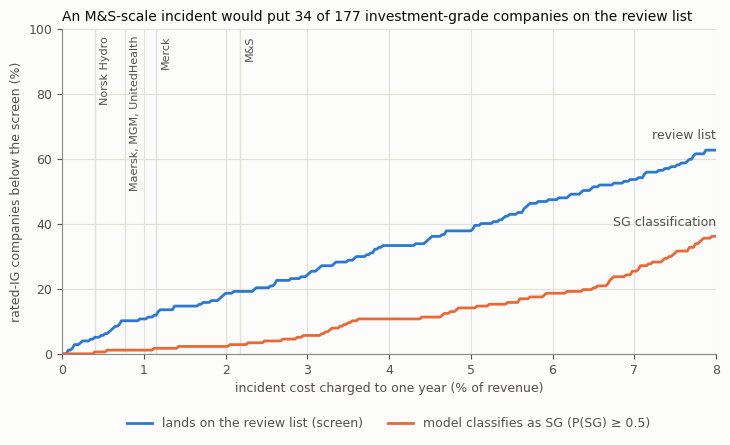

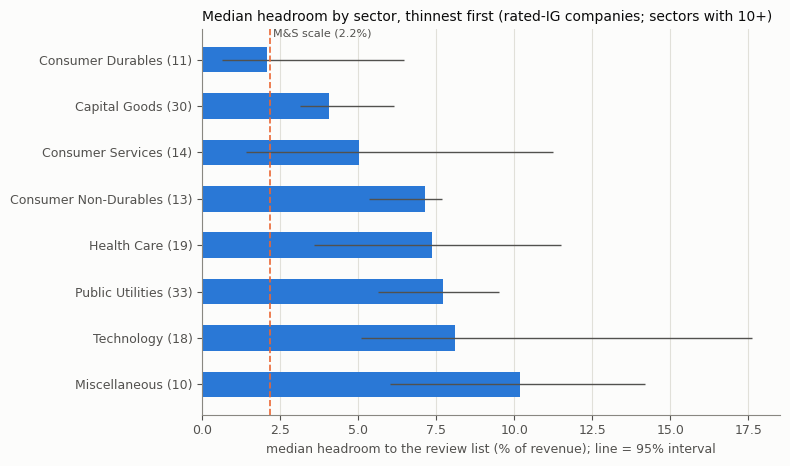

In [53]:
costs = np.linspace(0, 0.08, 321)
curve_screen = [(hr_screen[ig_all] <= x).mean() * 100 for x in costs]
curve_call = [(hr_call[ig_all] <= x).mean() * 100 for x in costs]
k_ms, n_ms = crossing_all["Marks & Spencer"][:2]
fig, ax = plt.subplots(figsize=(7.4, 4.6), facecolor=SURFACE)
ax.plot(costs * 100, curve_screen, color=BLUE, lw=2, label="lands on the review list (screen)")
ax.plot(costs * 100, curve_call, color=ORANGE, lw=2, label="model classifies as SG (P(SG) ≥ 0.5)")
for label, x in [("Norsk Hydro", 0.0040), ("Maersk, MGM,\nUnitedHealth", 0.0077), ("Merck", 0.0115), ("M&S", 0.0217)]:
    ax.axvline(x * 100, color=GRID, lw=1, zorder=0)
    ax.text(x * 100 + 0.06, 98, label.replace("\n", " "), fontsize=8, color=INK2, va="top", ha="left", rotation=90)
ax.text(costs[-1] * 100, curve_screen[-1] + 2.5, "review list", color=INK2, fontsize=9, ha="right", va="bottom")
ax.text(costs[-1] * 100, curve_call[-1] + 2.5, "SG classification", color=INK2, fontsize=9, ha="right", va="bottom")
style(ax, "incident cost charged to one year (% of revenue)", "rated-IG companies below the screen (%)")
ax.set_ylim(0, 100); ax.set_xlim(0, 8)
ax.set_title(f"An M&S-scale incident would put {k_ms} of {n_ms} investment-grade companies on the review list",
             loc="left", fontsize=10, color=INK)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=9, labelcolor=INK2)
fig.tight_layout(); fig.savefig(FIG / "fig_headroom_curve.png", dpi=150, facecolor=SURFACE); plt.show()

shown_s = headroom_sectors[~headroom_sectors.small]
ci_s = shown_s[["ci_lo", "ci_hi"]].to_numpy()
fig, ax = plt.subplots(figsize=(8, 0.42 * len(shown_s) + 1.4), facecolor=SURFACE)
y = np.arange(len(shown_s))[::-1]
ax.barh(y, shown_s["median headroom"] * 100, height=0.55, color=BLUE)
ax.hlines(y, ci_s[:, 0] * 100, ci_s[:, 1] * 100, color=INK2, lw=1)
ax.axvline(MS * 100, color=ORANGE, lw=1.2, ls="--")
ax.text(MS * 100 + 0.1, y.max() + 0.45, "M&S scale (2.2%)", color=INK2, fontsize=8, va="bottom")
ax.set_yticks(y); ax.set_yticklabels([f"{s} ({n})" for s, n in zip(shown_s.index, shown_s.companies)], fontsize=9, color=INK2)
style(ax, "median headroom to the review list (% of revenue); line = 95% interval", "")
ax.grid(axis="y", visible=False)
ax.set_title("Median headroom by sector, thinnest first (rated-IG companies; sectors with 10+)", loc="left", fontsize=10, color=INK)
fig.tight_layout(); fig.savefig(FIG / "fig_headroom_by_sector.png", dpi=150, facecolor=SURFACE); plt.show()

## 12. The internal grades on the holdout, and the cyber migration table
The six grades set in §6 are checked here on the holdout, and the cyber result is read as moves between them: how many companies drop a grade after an incident.

**How many grades, read on the holdout.** The number was chosen in §6 on training companies. As a check, the optimum cut-offs for 4 to 7 grades are read on the holdout: only the 4-grade optimum rises grade by grade there. The round 6-grade cut-offs actually used do not quite either: IG-3 comes out one point below IG-2 on the holdout (SG rate 0.32 against 0.33, with overlapping intervals; the table after this one), and IG-2 fails the Jeffreys test (0.22 predicted, 0.33 observed). With 123 holdout companies a single grade can come out of order by chance, which is why the choice is made on 25 training splits, not on this one draw; it is reported, not corrected on the holdout.

In [54]:
supported = {}
for k in (4, 5, 6, 7):
    cuts_k = optimal_cuts(dev_p, dev_y, k)
    rates = test.SG.groupby(to_grade(test.p_sg, cuts_k)).mean().reindex(range(k)).to_numpy()
    supported[k] = {"cut_points": cuts_k, "holdout_sg_rate": rates, "rises_every_grade": bool(np.all(np.diff(rates) > 0))}
    print(f"{k} grades: cut-points {np.round(cuts_k, 3).tolist()} | holdout SG rate by grade {np.round(rates, 2).tolist()}"
          f" | rises grade by grade: {supported[k]['rises_every_grade']}")
keep("grade_scale_choice", {"min_share": 0.10, "by_number_of_grades": supported, "optimum": optimum, "used": GRADE_CUTS,
                            "used_share_training": fixed_share, "used_sg_rate_training": fixed_rate,
                            "fit_kept_vs_optimum": fit_kept, "grade_count_check_training": grade_count})

4 grades: cut-points [0.22, 0.501, 0.825] | holdout SG rate by grade [0.16, 0.34, 0.53, 0.91] | rises grade by grade: True
5 grades: cut-points [0.173, 0.308, 0.559, 0.825] | holdout SG rate by grade [0.13, 0.34, 0.31, 0.59, 0.91] | rises grade by grade: False
6 grades: cut-points [0.173, 0.308, 0.501, 0.68, 0.879] | holdout SG rate by grade [0.13, 0.34, 0.33, 0.44, 0.74, 0.93] | rises grade by grade: False
7 grades: cut-points [0.147, 0.22, 0.308, 0.501, 0.68, 0.879] | holdout SG rate by grade [0.1, 0.26, 0.36, 0.33, 0.44, 0.74, 0.93] | rises grade by grade: False


**Checks on the holdout,** with the tests the ECB asks banks to report per grade (Instructions for reporting the validation results of internal models, 2019): calibration by the Jeffreys test (one-sided: a small p-value means the grade under-predicts), ranking power (AUC on the grades against AUC on the raw P(SG)) and concentration (Herfindahl index: 0 = spread evenly, 1 = all in one grade). Firm-years of one company are not independent, so the Jeffreys test rejects too easily (BCBS Working Paper 14 warns that correlation inflates such tests); the intervals resample companies. The last line shows how often a training company keeps its grade when the folds change (the three CV seeds).

In [55]:
def jeffreys_p(n, d, predicted):
    """ECB Jeffreys test, one-sided: p-value of H0 'the predicted rate is at least the true rate'; a small value = under-prediction."""
    return float(beta_dist.cdf(predicted, d + 0.5, n - d + 0.5))


def herfindahl_ecb(shares):
    """ECB concentration index of the grade shares: 0 = spread evenly across grades, 1 = all in one grade."""
    k = len(shares); cv = np.sqrt(k * np.sum((np.asarray(shares) - 1 / k) ** 2)); return float(1 + np.log((cv ** 2 + 1) / k) / np.log(k))


test["scale_grade"] = to_grade(test.p_sg)
dev_g = to_grade(dev_p)
bounds = list(zip([0.0] + GRADE_CUTS, GRADE_CUTS + [1.0]))
rows = []
for g, name in enumerate(GRADE_NAMES):
    held = test[test.scale_grade == g]
    ci = company_ci(lambda f, g=g: f.SG[f.scale_grade == g].mean(), test)
    rows.append({"grade": name, "meaning": GRADE_MEANING[g], "P(SG)": f"{bounds[g][0]:g}-{bounds[g][1]:g}",
                 "training share (CV)": np.mean(dev_g == g), "training SG rate (CV)": dev_y[dev_g == g].mean(),
                 "holdout firm-years": len(held), "holdout mean P(SG)": held.p_sg.mean(), "holdout SG rate": held.SG.mean(),
                 "95% CI": f"[{ci[0]:.2f}, {ci[1]:.2f}]", "Jeffreys p": jeffreys_p(len(held), held.SG.sum(), held.p_sg.mean())})
scale = pd.DataFrame(rows).set_index("grade")
print(scale.round(3).to_string())

seed_grades = np.column_stack([to_grade(platt(oof)) for oof, _ in champion_runs])
grade_shares = scale["holdout firm-years"].to_numpy() / len(test)
scale_checks = {"rises_grade_by_grade_holdout": bool(np.all(np.diff(scale["holdout SG rate"]) > 0)),
                "grades_failing_jeffreys_5pct": int((scale["Jeffreys p"] < 0.05).sum()),
                "auc_on_grades_holdout": roc_auc_score(test.SG, test.scale_grade), "auc_on_p_sg_holdout": roc_auc_score(test.SG, test.p_sg),
                "herfindahl_ecb_holdout": herfindahl_ecb(grade_shares), "largest_grade_share_holdout": grade_shares.max(),
                "same_grade_in_all_3_cv_seeds": np.mean(seed_grades.min(1) == seed_grades.max(1))}
print({k: round(v, 3) if isinstance(v, float) else v for k, v in scale_checks.items()})
keep("grade_scale_holdout", {"by_grade": scale.to_dict(orient="index"), **scale_checks})

             meaning     P(SG)  training share (CV)  training SG rate (CV)  holdout firm-years  holdout mean P(SG)  holdout SG rate        95% CI  Jeffreys p
grade                                                                                                                                                        
IG-1          strong    0-0.15                0.205                  0.092                  79               0.108            0.101  [0.04, 0.20]       0.560
IG-2           solid  0.15-0.3                0.226                  0.221                  96               0.224            0.333  [0.19, 0.48]       0.007
IG-3   near the line   0.3-0.5                0.208                  0.398                  73               0.399            0.315  [0.18, 0.45]       0.931
SG-1   near the line   0.5-0.7                0.133                  0.596                  54               0.597            0.444  [0.31, 0.58]       0.988
SG-2            weak  0.7-0.85                0.108 

**The portfolio by grade:** every company on its latest statement, scored by a model that never saw it (the cross-fitted scores of §11), with the agency ratings its companies hold.

In [56]:
allco["scale_grade"] = to_grade(allco.p_sg)
agency_mix = pd.crosstab(allco.scale_grade, pd.Categorical(allco.band_idx.map(dict(enumerate(GRADES))), GRADES), normalize="index")
portfolio_grades = pd.DataFrame({
    "grade": GRADE_NAMES, "meaning": GRADE_MEANING,
    "companies": allco.scale_grade.value_counts().reindex(range(len(GRADE_NAMES)), fill_value=0).to_numpy(),
    "rated SG by agencies": allco.groupby("scale_grade").SG.mean().reindex(range(len(GRADE_NAMES))).to_numpy(),
    "agency ratings held (15%+)": [", ".join(f"{b} {s:.0%}" for b, s in agency_mix.loc[g].sort_values(ascending=False).items() if s >= 0.15)
                                   for g in range(len(GRADE_NAMES))]}).set_index("grade")
portfolio_grades["share"] = portfolio_grades.companies / len(allco)
print(portfolio_grades.round(2).to_string())
keep("grade_scale_portfolio", portfolio_grades.to_dict(orient="index"))

             meaning  companies  rated SG by agencies        agency ratings held (15%+)  share
grade                                                                                         
IG-1          strong         99                  0.10                    BBB 39%, A 38%   0.17
IG-2           solid        123                  0.25            BBB 45%, A 26%, BB 20%   0.21
IG-3   near the line        120                  0.38                   BBB 50%, BB 29%   0.20
SG-1   near the line         95                  0.58            BBB 34%, BB 33%, B 20%   0.16
SG-2            weak         70                  0.76            B 34%, BB 33%, BBB 20%   0.12
SG-3       very weak         85                  0.88  B 45%, BB 25%, CCC and below 19%   0.14


**The cyber migration table.** Each company's latest statement is graded before and after an incident cost, with the cross-fitted models of §11, so no company is graded by a model that saw it. Rows are the grade before, columns the grade after. The model is monotone, so an incident can only move a company down. SG-3 is a floor: without default data there is no grade below it, so SG-3 companies cannot be seen to move.

The reference is a **normal year**: the same company's grade on its statement one year later, from the same cross-fitted scores. The ECB's matrix weighted bandwidth (MWB) summarises how far companies move, downgrades and upgrades separately, on a 0–1 scale (larger = longer moves).

In [57]:
def migration_matrix(before, after):
    """Companies by grade before (rows) and grade after (columns)."""
    k = len(GRADE_NAMES)
    m = pd.crosstab(pd.Categorical(before, range(k)), pd.Categorical(after, range(k)), dropna=False)
    return m.set_axis(GRADE_NAMES, axis=0).set_axis(GRADE_NAMES, axis=1).rename_axis(index="grade before", columns="grade after")


def mwb(m):
    """ECB matrix weighted bandwidth (validation reporting instructions, 2.5.5.1): (downgrades, upgrades), each on a 0-1 scale."""
    n = m.sum(1).to_numpy(float); p = m.to_numpy(float) / np.maximum(n, 1)[:, None]; k = len(n)
    reach = lambda i: max(abs(i - (k - 1)), i)
    down = sum(abs(i - j) * n[i] * p[i, j] for i in range(k) for j in range(i + 1, k))
    up = sum(abs(i - j) * n[i] * p[i, j] for i in range(k) for j in range(i))
    down_norm = sum(reach(i) * n[i] * p[i, i + 1:].sum() for i in range(k))
    up_norm = sum(reach(i) * n[i] * p[i, :i].sum() for i in range(k))
    return (down / down_norm if down_norm else 0.0, up / up_norm if up_norm else 0.0)


def moves(before, after):
    """Per starting grade: companies, and the share that stay, drop one grade or drop two or more."""
    d = pd.Series(np.asarray(after) - np.asarray(before)); b = pd.Series(np.asarray(before))
    out = pd.DataFrame({"companies": b.value_counts(), "stay": (d == 0).groupby(b).mean(), "down 1": (d == 1).groupby(b).mean(),
                        "down 2+": (d >= 2).groupby(b).mean(), "up 1+": (d <= -1).groupby(b).mean()})
    return out.reindex(range(len(GRADE_NAMES))).set_axis(GRADE_NAMES)


grade_before = allco.scale_grade.to_numpy()
grade_after = {}
for incident, cost in zip(ANCHORS.incident, ANCHORS.share_of_revenue):
    after = pd.Series(-1, index=allco.index)
    for names_f, score_f, ref_f in folds_cf:
        rows_f = allco[allco.Name.isin(names_f)]
        assert np.allclose(score_f(rows_f), rows_f.p_sg)                      # the same models as §11
        after[rows_f.index] = to_grade(score_f(incident_shock(rows_f, cost, ref_f)))
    assert (after.to_numpy() >= grade_before).all()                          # an incident never improves a grade
    grade_after[incident] = after.to_numpy()

by_incident = pd.DataFrame({inc: {"share of revenue": cost, "drop 1+ grade": np.mean(grade_after[inc] > grade_before),
                                  "drop 2+ grades": np.mean(grade_after[inc] - grade_before >= 2),
                                  "companies dropping 2+": int(np.sum(grade_after[inc] - grade_before >= 2)),
                                  "MWB down": mwb(migration_matrix(grade_before, grade_after[inc]))[0]}
                            for inc, cost in zip(ANCHORS.incident, ANCHORS.share_of_revenue)}).T
print(f"{len(allco)} companies, latest statement, cross-fitted:")
print(by_incident.to_string(formatters={"share of revenue": "{:.2%}".format, "drop 1+ grade": "{:.1%}".format,
                                        "drop 2+ grades": "{:.1%}".format, "MWB down": "{:.2f}".format}))
ms_matrix = migration_matrix(grade_before, grade_after["Marks & Spencer"])
print("\nM&S scale (2.17% of revenue), companies:\n", ms_matrix.to_string())
print(moves(grade_before, grade_after["Marks & Spencer"]).round(2).to_string())

# The normal year: the same company's grade one year later (cross-fitted scores of every firm-year)
cf_all = pd.Series(np.nan, index=data.index)
for names_f, score_f, _ in folds_cf:
    in_fold = data.Name.isin(names_f)
    cf_all[in_fold] = score_f(data[in_fold])
yearly = (data.assign(scale_grade=to_grade(cf_all)).sort_values("Date", kind="stable").groupby(["Name", "year"]).tail(1)
          .sort_values(["Name", "year"], kind="stable"))
following = yearly.groupby("Name")[["scale_grade", "year"]].shift(-1)
one_year = (following.year - yearly.year) == 1
normal_before, normal_after = yearly.scale_grade[one_year].to_numpy(), following.scale_grade[one_year].astype(int).to_numpy()
normal_matrix = migration_matrix(normal_before, normal_after)
normal_moves = {"pairs": len(normal_before), "companies": yearly.Name[one_year].nunique(), "stay": np.mean(normal_after == normal_before),
                "down 1": np.mean(normal_after - normal_before == 1), "down 2+": np.mean(normal_after - normal_before >= 2),
                "up 1+": np.mean(normal_after < normal_before), "mwb_down": mwb(normal_matrix)[0], "mwb_up": mwb(normal_matrix)[1]}
print(f"\nnormal year: {normal_moves['pairs']} consecutive-year pairs from {normal_moves['companies']} companies (row shares)\n",
      normal_matrix.div(normal_matrix.sum(1), axis=0).round(2).to_string())
print({k: round(v, 3) if isinstance(v, float) else v for k, v in normal_moves.items()})
keep("cyber_migration", {"companies": len(allco), "by_incident": by_incident.to_dict(orient="index"),
                         "ms_matrix": ms_matrix.to_dict(orient="index"),
                         "ms_moves_by_grade": moves(grade_before, grade_after["Marks & Spencer"]).to_dict(orient="index")})
keep("normal_year_migration", {**normal_moves, "matrix": normal_matrix.to_dict(orient="index")})

592 companies, latest statement, cross-fitted:
                share of revenue drop 1+ grade drop 2+ grades  companies dropping 2+ MWB down
Norsk Hydro                0.40%          6.9%           0.3%                    2.0     0.30
Maersk                     0.81%         11.7%           0.7%                    4.0     0.30
MGM Resorts                0.68%         11.0%           0.7%                    4.0     0.30
UnitedHealth               0.77%         11.5%           0.7%                    4.0     0.30
Merck                      1.15%         16.9%           1.4%                    8.0     0.31
Marks & Spencer            2.17%         31.1%           4.9%                   29.0     0.32

M&S scale (2.17% of revenue), companies:
 grade after   IG-1  IG-2  IG-3  SG-1  SG-2  SG-3
grade before                                    
IG-1            77    20     2     0     0     0
IG-2             0    76    38     8     1     0
IG-3             0     0    67    41    12     0
SG-1   

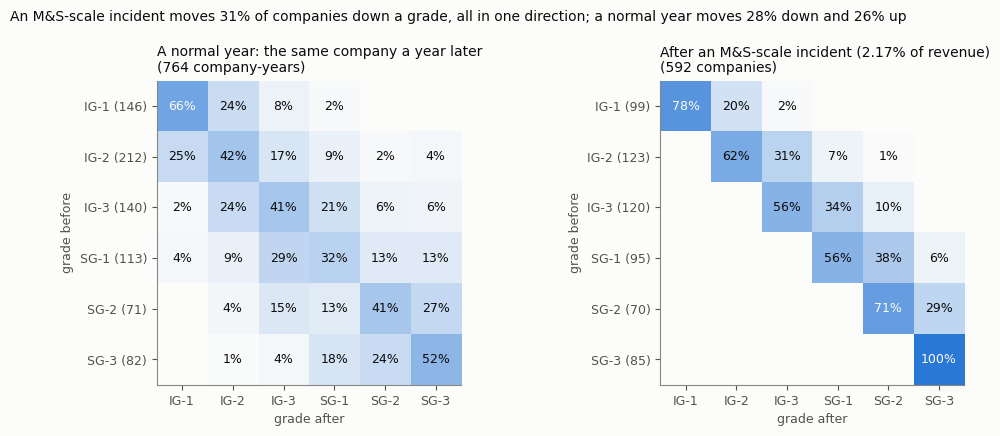

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.4), facecolor=SURFACE)
ramp = LinearSegmentedColormap.from_list("blue_ramp", [SURFACE, BLUE])     # one hue, light to dark: share of the row
panels = [(normal_matrix, f"A normal year: the same company a year later\n({normal_moves['pairs']} company-years)"),
          (ms_matrix, f"After an M&S-scale incident (2.17% of revenue)\n({len(allco)} companies)")]
for ax, (m, title) in zip(axes, panels):
    share = m.div(m.sum(1), axis=0).to_numpy()
    ax.imshow(share, cmap=ramp, vmin=0, vmax=1)
    for i in range(share.shape[0]):
        for j in range(share.shape[1]):
            if m.iat[i, j]:
                label = f"{share[i, j]:.0%}" if share[i, j] >= 0.005 else "<1%"
                ax.text(j, i, label, ha="center", va="center", fontsize=9, color=SURFACE if share[i, j] >= 0.65 else INK)
    style(ax, "grade after", "grade before")
    ax.grid(False)
    ax.set_xticks(range(len(GRADE_NAMES)), GRADE_NAMES)
    ax.set_yticks(range(len(GRADE_NAMES)), [f"{g} ({n})" for g, n in zip(GRADE_NAMES, m.sum(1))])
    ax.set_title(title, loc="left", fontsize=10, color=INK)
fig.suptitle(f"An M&S-scale incident moves {by_incident.loc['Marks & Spencer', 'drop 1+ grade']:.0%} of companies down a grade,"
             f" all in one direction; a normal year moves {normal_moves['down 1'] + normal_moves['down 2+']:.0%} down and {normal_moves['up 1+']:.0%} up",
             x=0.01, ha="left", fontsize=10, color=INK)
fig.tight_layout(); fig.savefig(FIG / "fig_cyber_migration.png", dpi=150, facecolor=SURFACE); plt.show()

**Reading:** an M&S-scale incident moves 31% of companies down at least one grade, and 4.9% (29 companies) down two or more. At the three mid-size anchors (0.68%–0.81% of revenue) 11–12% drop a grade and 4 companies drop two. The grades nearest the line are the most fragile: 44% of IG-3 and 44% of SG-1 companies drop at least one grade at M&S scale. A normal year moves companies in both directions: 46% keep their grade, 28% go down and 26% go up, because the grades read each year's statements (point-in-time), while agency ratings aim to look through the cycle. So an M&S-scale incident moves more companies down than a normal year does (31% against 28%), and all in one direction. For monitoring, a one-grade drop is too common to act on; a drop of two or more grades (about 10% of company-years in a normal year) or a move across the 0.5 line (from IG-3 into SG-1 or below) is a usable alert. The table is a scenario: the cost is charged to one year's statements, and SG-3 cannot fall further.

**Rules on top of the model.** Banks combine a model grade with written rules and analyst overrides (Basel II para 428; CRR Art 172(3); EBA GL/2017/16 paras 201–207). A rule earns its place only if it adds what the model misses, so each candidate is tested on the training companies, on scores from models that never saw the company; the holdout only shows what the adopted rule changes.
1. **Eligibility:** input that fails the 02 data checks gets no grade (`score()` rejects it). In deployment, statements older than about 18 months, or with many missing inputs, go to manual review. Banks and insurers are rated under their own agency methods, so a bank-like balance sheet deserves an analyst's look; it is noted, not made a rule (2 of the 17 Finance companies, 01 section 14).
2. **Floor:** negative equity puts a company at SG-1 or worse (tested below, with one rejected candidate).
3. **Analyst overrides** (a policy, not code): at most one grade, with a reason from a fixed list; downgrades need no approval, upgrades do; the override rate and the later outcome of overridden companies are tracked. Many overrides in the same direction mean the model needs fixing.

In [59]:
honest = train.assign(p=np.mean([platt(oof) for oof, _ in champion_runs], axis=0))   # training companies, out of fold: the holdout is not used to choose
honest["scale_grade"] = to_grade(honest.p)
sg1 = GRADE_NAMES.index("SG-1")
rule_candidates = {"negative equity": honest.negative_equity == 1,
              "losses and negative operating cash flow": (honest.roe_negative == 1) & (honest.ocf_negative == 1)}
rule_rows = {}
for name, fires in rule_candidates.items():
    moved = fires & (honest.scale_grade < sg1)
    rule_rows[name] = {"fires (firm-years)": int(fires.sum()), "would move (firm-years)": int(moved.sum()),
                       "would move (companies)": honest.Name[moved].nunique(),
                       "their mean P(SG)": honest.p[moved].mean() if moved.any() else np.nan,
                       "their actual SG rate": honest.SG[moved].mean() if moved.any() else np.nan}
rule_table = pd.DataFrame(rule_rows).T
print(rule_table.round(2).to_string())
print("SG rate by grade, training companies out of fold:", dict(zip(GRADE_NAMES, honest.groupby("scale_grade").SG.mean().round(2))))
ruled, rule_moved = assign_grade(test, test.p_sg)
print(f"holdout AUC on grades: model {roc_auc_score(test.SG, test.scale_grade):.3f} | with the rule {roc_auc_score(test.SG, ruled):.3f}"
      f" ({int(rule_moved.sum())} holdout firm-years moved)")
keep("grade_rules", {"candidates": rule_table.to_dict(orient="index"), "adopted": GRADE_SCALE["rule"],
                     "holdout_auc_model": roc_auc_score(test.SG, test.scale_grade), "holdout_auc_with_rule": roc_auc_score(test.SG, ruled),
                     "holdout_moved": int(rule_moved.sum())})

                                         fires (firm-years)  would move (firm-years)  would move (companies)  their mean P(SG)  their actual SG rate
negative equity                                        84.0                     24.0                    10.0              0.35                  0.62
losses and negative operating cash flow                28.0                      0.0                     0.0               NaN                   NaN
SG rate by grade, training companies out of fold: {'IG-1': 0.09, 'IG-2': 0.21, 'IG-3': 0.39, 'SG-1': 0.61, 'SG-2': 0.78, 'SG-3': 0.92}
holdout AUC on grades: model 0.784 | with the rule 0.784 (2 holdout firm-years moved)


**Reading:** on the training companies the negative-equity floor fires on 84 firm-years. On 24 of them (10 companies) the model gave a grade below SG-1, with a mean P(SG) of 0.35, while 62% were rated SG: these companies are riskier than their model grade, and the floor moves them the right way. It is a conservative rule, the kind EBA GL/2017/16 (para 203) says should not be limited. Only 2 holdout firm-years are affected, too few to show on the holdout AUC (0.784 with and without the rule). The second candidate, losses with negative operating cash flow, never changes a grade: the model already puts those companies at SG-1 or worse, so it is not adopted.

**Monitoring and recalibration.** These cut-offs are a first version, set on 469 training companies. Each year, on new statements and ratings:
- **Order and level:** does the SG rate still rise grade by grade, and does each grade pass the Jeffreys test?
- **Concentration and movement:** is any grade too crowded (Herfindahl), and do companies move between grades about as often as in the normal year above (MWB)?
- **Overrides:** how many, in which direction, and how did the overridden companies turn out?

If the order holds but a grade's level drifts, re-fit the cut-offs with the same binning (§6). If the ranking breaks, the model is retrained first (README, monitoring roadmap). With more companies, the same binning can be re-run for 7 grades, the regulatory minimum.

## Appendix A. The full-rating approach we tested: a 6-grade band
Predicting the grade itself is the obvious use of a ratings dataset, so it was tested with the same inputs, constraints and validation as the IG/SG model. Kept as an appendix: on the holdout its exact grade barely beats always answering BBB (the table shows both), and its regressor keeps its own, untuned settings (500 trees x 15 leaves) and one CV seed.

A monotone LightGBM regressor on the grade (0 = AA and above … 5 = CCC and below), rounded. It is compared with always answering BBB, the best constant.

In [60]:
def band_scores(frame):
    e = np.abs(frame.grade.values - frame.band_pred.values)
    return {"exact": (e == 0).mean(), "within_one_grade": (e <= 1).mean(), "mean_error_grades": e.mean()}

band_oof = np.zeros(len(train))
for fit_rows, score_rows in StratifiedGroupKFold(5, shuffle=True, random_state=11).split(train, train.grade, groups=train.Name):
    band_oof[score_rows] = band_model().fit(train.iloc[fit_rows], train.grade.values[fit_rows]).predict(train.iloc[score_rows])
train["band_score"] = band_oof
train["band_pred"] = np.clip(np.rint(band_oof), 0, 5)
band_fit = band_model().fit(train, train.grade)
test["band_score"] = band_fit.predict(test)
test["band_pred"] = np.clip(np.rint(test.band_score), 0, 5)

band = pd.DataFrame({"band (CV)": band_scores(train), "always BBB (CV)": band_scores(train.assign(band_pred=2)),
                     "band (holdout)": band_scores(test), "always BBB (holdout)": band_scores(test.assign(band_pred=2))}).T
print(band.round(2).to_string())
print("within one grade, by true grade (CV):", (np.abs(train.grade - train.band_pred) <= 1).groupby(train.grade).mean().round(2).set_axis(GRADES).to_dict())
keep("band", band.to_dict(orient="index"))
keep("band_within_one_by_grade_cv", (np.abs(train.grade - train.band_pred) <= 1).groupby(train.grade).mean().set_axis(GRADES).to_dict())

                      exact  within_one_grade  mean_error_grades
band (CV)              0.43              0.90               0.68
always BBB (CV)        0.33              0.77               0.94
band (holdout)         0.42              0.89               0.70
always BBB (holdout)   0.34              0.77               0.90
within one grade, by true grade (CV): {'AA and above': 0.61, 'A': 0.91, 'BBB': 0.97, 'BB': 0.95, 'B': 0.81, 'CCC and below': 0.6}


### How the grade model compares, and why the main product is IG/SG
Exact grade, within one grade and mean error, against four references: always answering BBB (the best constant), a random guess (uniform over the 6 bands, and weighted by the training mix; expected values, computed exactly), and two agencies rating the same company (one pair per company, ratings at most 365 days apart, in scope). Then where the grade model's predictions land, and the IG/SG question asked of both models on the holdout.

In [61]:
mix = data.grade.value_counts(normalize=True).sort_index().set_axis(GRADES)
print("share of firm-years by band (in scope):", mix.round(3).to_dict(), f"| BBB + BB: {mix['BBB'] + mix['BB']:.0%}")


def random_scores(true, probs):
    """Expected exact, within-one and mean error of a guess drawn from `probs` over the 6 bands."""
    d = np.abs(np.asarray(true)[:, None] - np.arange(6)[None, :])
    return {"exact": float((probs * (d == 0)).sum(1).mean()), "within_one_grade": float((probs * (d <= 1)).sum(1).mean()),
            "mean_error_grades": float((probs * d).sum(1).mean())}


train_mix = train.grade.value_counts(normalize=True).reindex(range(6), fill_value=0).to_numpy()
r = data[["Name", "agency", "Date", "grade", "letter_idx", "SG"]]
pairs = r.merge(r, on="Name")
pairs = pairs[(pairs.agency_x < pairs.agency_y) & ((pairs.Date_x - pairs.Date_y).abs().dt.days <= 365)]
pairs = pairs.assign(gap=(pairs.Date_x - pairs.Date_y).abs()).sort_values(["Name", "gap"]).groupby("Name").head(1)
agency_label = f"two agencies, same company ({len(pairs)} companies)"
comparison = pd.DataFrame({
    "grade model (CV)": band_scores(train), "grade model (holdout)": band_scores(test),
    "always BBB (holdout)": band_scores(test.assign(band_pred=2)),
    "random, uniform (holdout)": random_scores(test.grade, np.full(6, 1 / 6)),
    "random, training mix (holdout)": random_scores(test.grade, train_mix),
    agency_label: {"exact": (pairs.grade_x == pairs.grade_y).mean(), "within_one_grade": ((pairs.grade_x - pairs.grade_y).abs() <= 1).mean(),
                   "mean_error_grades": (pairs.grade_x - pairs.grade_y).abs().mean()}}).T
print(comparison.round(3).to_string())
same_letter, same_side = (pairs.letter_idx_x == pairs.letter_idx_y).mean(), (pairs.SG_x == pairs.SG_y).mean()
print(f"two agencies on the same company: same letter (10 letters) {same_letter:.0%} | same 6-grade band {comparison.loc[agency_label, 'exact']:.0%}"
      f" | same IG/SG side {same_side:.0%}")

name = dict(enumerate(GRADES))
conf = pd.crosstab(test.grade.map(name), test.band_pred.astype(int).map(name), rownames=["true band"], colnames=["predicted band"])
conf = conf.reindex(index=GRADES, columns=GRADES, fill_value=0)
print("\nholdout firm-years, true band (rows) vs predicted band (columns):\n", conf.to_string())
print("predicted bands, share of holdout firm-years:", test.band_pred.astype(int).map(name).value_counts(normalize=True).reindex(GRADES, fill_value=0).round(2).to_dict())

bb_t = test.Rating.isin(["BBB", "BB"])
ig_sg = pd.DataFrame({m: {"AUC, IG vs SG": roc_auc_score(test.SG, s), "AUC, BBB vs BB": roc_auc_score(test.SG[bb_t], s[bb_t])}
                      for m, s in [("grade model score", test.band_score), ("dedicated SG model", test.p_sg)]}).T
print("\nthe IG/SG question asked of both models (holdout firm-years):\n", ig_sg.round(3).to_string())
keep("rating_attempt", {"band_mix_firm_years": mix.to_dict(), "bbb_plus_bb_share": mix["BBB"] + mix["BB"],
                        "comparison": comparison.to_dict(orient="index"), "agency_pairs_companies": len(pairs),
                        "agency_same_letter": same_letter, "agency_same_band": comparison.loc[agency_label, "exact"], "agency_same_side": same_side,
                        "holdout_confusion": conf.to_dict(orient="index"),
                        "predicted_band_share_holdout": test.band_pred.astype(int).map(name).value_counts(normalize=True).reindex(GRADES, fill_value=0).to_dict(),
                        "ig_sg_from_each_model": ig_sg.to_dict(orient="index")})

share of firm-years by band (in scope): {'AA and above': 0.047, 'A': 0.196, 'BBB': 0.331, 'BB': 0.242, 'B': 0.149, 'CCC and below': 0.036} | BBB + BB: 57%
                                            exact  within_one_grade  mean_error_grades
grade model (CV)                            0.428             0.899              0.685
grade model (holdout)                       0.418             0.885              0.702
always BBB (holdout)                        0.337             0.770              0.905
random, uniform (holdout)                   0.167             0.490              1.678
random, training mix (holdout)              0.235             0.628              1.296
two agencies, same company (152 companies)  0.559             0.947              0.493
two agencies on the same company: same letter (10 letters) 55% | same 6-grade band 56% | same IG/SG side 86%

holdout firm-years, true band (rows) vs predicted band (columns):
 predicted band  AA and above   A  BBB  BB   B  CCC and belo

**How often the band moves** between a company's consecutive ratings by the same agency, against the agency's own grade.

In [62]:
band_seq = train.sort_values(["Name", "agency", "Date"])
prev = band_seq.groupby(["Name", "agency"])[["grade", "band_pred", "band_score"]].shift()
moved = band_seq.assign(agency_moved=band_seq.grade != prev.grade, band_moved=band_seq.band_pred != prev.band_pred,
                   small=(band_seq.band_score - prev.band_score).abs() < 0.5)[prev.grade.notna()]
small_share = moved.small[moved.band_moved].mean()
print(f"{len(moved)} consecutive pairs | agency grade changed {moved.agency_moved.mean():.0%} | band changed {moved.band_moved.mean():.0%}, "
      f"of which {small_share:.0%} on a score move under half a grade")
print("→ mostly point-in-time (the model reads each year's statements), partly noise at the grade cut-offs.")
keep("band_churn", {"pairs": len(moved), "agency_changed": moved.agency_moved.mean(), "band_changed": moved.band_moved.mean(),
                    "band_changes_small_move_share": small_share})

861 consecutive pairs | agency grade changed 20% | band changed 43%, of which 28% on a score move under half a grade
→ mostly point-in-time (the model reads each year's statements), partly noise at the grade cut-offs.


## Appendix B. One answer per company: grade, plus a screen alert
The **screen alert** marks an IG-graded company that the review screen still catches. It is an internal prompt to look, not a rating action.

In [63]:
portfolio["band_pred"] = test.band_pred.loc[portfolio.index]
portfolio["tier"] = np.select([portfolio.band_pred >= 3, portfolio.screen], ["1 SG grade", "2 IG grade, screen alert"], "3 IG grade, no alert")
tiers = portfolio.groupby("tier").agg(companies=("SG", "size"), actual_SG_share=("SG", "mean"))
tiers["share_of_companies"] = tiers.companies / len(portfolio)
print(tiers.round(2).to_string())
keep("tiers_holdout_companies", tiers.to_dict(orient="index"))

                          companies  actual_SG_share  share_of_companies
tier                                                                    
1 SG grade                       59             0.69                0.48
2 IG grade, screen alert         23             0.35                0.19
3 IG grade, no alert             41             0.17                0.33


**Reading:** the SG-grade tier separates well. Among IG-graded companies the screen alert separates only a little, on a few dozen companies each, so it is a prompt to look, not a strong ranking.

## Appendix C. Cost rule
If a missed SG company costs k reviews, review a company when P(SG) × k ≥ 1, i.e. when P(SG) ≥ 1/k. Kept for reference: the recommended policy is the review budget (§7).

In [64]:
cost = pd.DataFrame([{"k": k, "threshold": 1 / k, "companies flagged": (portfolio.p_sg >= 1 / k).mean(),
                      "SG caught": (portfolio.p_sg >= 1 / k)[portfolio.SG == 1].mean()} for k in [2, 4, 10]])
print(cost.round(2).to_string(index=False))
keep("cost_rule_companies", cost.to_dict(orient="records"))

 k  threshold  companies flagged  SG caught
 2       0.50               0.46       0.71
 4       0.25               0.74       0.95
10       0.10               0.93       1.00


## 13. Numbers of record

In [65]:
record = RES / "numbers_of_record.json"
record.write_text(json.dumps(NOR, indent=1, ensure_ascii=False))   # written fresh, so no stale key survives
print(f"{len(NOR)} entries written to results/numbers_of_record.json")

60 entries written to results/numbers_of_record.json
